# Milo Differential Abundance Testing

### 0. Import relevant modules, set variables and define functions

In [1]:
import numpy as np
import pandas as pd
import scanpy as sc
import anndata
import matplotlib.pyplot as plt
plt.rcParams['figure.figsize']=(8,8) #rescale figures
sc.settings.verbosity = 3

import milopy.core as milo
import milopy.plot as milopl
import milopy.utils
from datetime import date

In [2]:
today = date.today()
date = today.strftime("%d_%m_%Y")

In [3]:
query_dataset_ipf = ['Banovich_Kropski_2020_disease', 'Kaminski_2020', 'Misharin_Budinger_2018_disease', 'Sheppard_2020']
query_dataset_healthy = ['Meyer_2021_3prime', 'Meyer_2021_5prime']
query_dataset_nucleus = ['Duong_lungMAP_unpubl', 'Eils_2020', 'Sun_2020_batch1', 'Sun_2020_batch2', 'Sun_2020_batch3', 'Sun_2020_batch4']

In [4]:
save_loc_healthy = "/home/jan.domke/storage_groups/ml01/workspace/jan.domke/Data/Data_Milo/New_higher_k/"
save_loc_ipf = "/home/jan.domke/storage_groups/ml01/workspace/jan.domke/Data/Data_Milo/New_higher_k/"
save_loc_nucleus = "/home/jan.domke/storage_groups/ml01/workspace/jan.domke/Data/Data_Milo/New_higher_k/"

In [5]:
def get_avg_da_per_cell(data):
    """
    Input: data
        whole anndata object (either denovo_recalc, denovo_ref, scarches_unlabeled, scarches_labeled)
    Output: cells_DA_avg
        vector containing the average logFC for all cells over the nhoods this cell is part of
    """
    
    
    # get vector with all cells and DA info: non-index cells have logFC of 0, index-cells have logFC != 0
    da_per_nhood = data.uns["nhood_adata"].obs[["index_cell","logFC"]]
    da_per_nhood.index = da_per_nhood.index_cell
    da_per_nhood = da_per_nhood["logFC"]
    
    # get cells x nhoods matrix with logFC values instead of neighborhood assignment
    cells_nh_DA = (data.obsm["nhoods"]).multiply(da_per_nhood)
    
    # average over logFC values for each nhood
    nh_DA_avg = cells_nh_DA.sum(axis=0).A1/cells_nh_DA.getnnz(axis=0)
    
    # get cells x nhoods matrix with average logFC values per nhood instead of nhood assignment
    cells_nh_DA_avg = (data.obsm["nhoods"]).multiply(nh_DA_avg)
    
    # get vector with average logFC for all cells over all nhoods each cell is part of
    cells_DA_avg = cells_nh_DA_avg.sum(axis=1).A1/cells_nh_DA.getnnz(axis=1)
    pd.DataFrame(cells_DA_avg).fillna(0, inplace=True)
    
    #output
    return cells_DA_avg

In [6]:
def run_milo_workflow(adata, name, embedding, query_dataset, save_loc, date=date, k = 50, n = 30, version="query/reference"):
    '''
    Runs complete Milo differential abundance workflow. 
    Input:
        adata: adata to test for differential abundance
        name: healthy/ipf/nucleus + denovo_recalc/denovo_ref/scarches_unlabeled/scarches_labeled (for saving plots)
        embedding: to use for creation of kNN: for denovo: scANVI, for scArches: scArches
        save_loc = path to folder where dataset should be saved
        date = only for output naming purposes
        k = 50 #number of neighbors for kNN
        n = 30 #number of pcs  for kNN
        version: "query/reference" or "disease/healthy" -> which condition should be tested with differential abundance
    Returns:
        - adapted adata object with milo values added
    '''   

    # Add condition_milo column
    if((version == "query/reference") | (version == "reference/query")):
        adata.obs["condition_milo"] = "reference"
        adata.obs.loc[adata.obs.dataset.isin(query_dataset),"condition_milo"] = "query"
    elif((version == "disease/healthy") | (version == "healthy/disease")):
        #adata.obs["condition_milo"] = ["Disease" if cond in ["IPF"] else "Healthy" for cond in adata.obs["condition_milo"]]
        adata.obs["condition_milo"] = "healthy"
        adata.obs.loc[adata.obs.condition=="IPF","condition_milo"] = "disease"


    
    
    
    #  Calculate nearest neighbors and the umap representation
    sc.pp.neighbors(adata, n_neighbors=k, n_pcs=n, use_rep="X_"+embedding)
    sc.tl.umap(adata)
    print("Show plot: UMAP of "+ name + " showing scanvi_label, dataset and condition.")
    sc.pl.umap(adata, color=["scanvi_label","dataset", "condition_milo"], save=f"_{name}_{date}.png")


    # Construct milo neighborhoods: assign cells to a set of representative neighbourhoods on the KNN graph. Assignment is stored in adata.obsm["nhoods"] 
    milo.make_nhoods(adata, prop=0.1)

    #Visualize the distribution of neighborhood sizes 
    nhood_size = np.array(adata.obsm["nhoods"].sum(0)).ravel()
    print("Show plot: Distribution of neighborhood sizes.")
    plt.hist(nhood_size, bins=100);
    plt.savefig(f"{save_loc}{name}_distr_nhood_{date}.png")

    # Count how many cells from each sample (=sample_col) are in each neighborhood. 
    # This adds adata.uns["nhood_adata"], storing an anndata object where obs correespond to neighborhoods, var corresponds to samples and  .X stores the number of cells from each sample counted in a neighborhood.
    milo.count_nhoods(adata, sample_col="sample")
    # Test for differential abundance using condition_milo as condition
    adata.obs["condition_milo_continuous"] = adata.obs["condition_milo"].cat.codes
    milo.DA_nhoods(adata, design="~condition_milo_continuous")
    
    # The differential abundance test results are stored in adata.uns["nhood_adata"].obs. In particular:
    # logFC stores the log-Fold Change in abundance (i.e. the slope of the linear model)
    # PValue stores the p-value for the test
    # SpatialFDR stores the p-values adjusted for multiple testing (accounting for overlap between neighbourhoods)
    print("Show plot: log-Fold Changes for "+name)
    old_figsize = plt.rcParams["figure.figsize"]
    plt.rcParams["figure.figsize"] = [10,5]
    plt.subplot(1,2,1)
    plt.hist(adata.uns["nhood_adata"].obs.PValue, bins=50);
    plt.xlabel("P-Vals");
    plt.subplot(1,2,2)
    plt.plot(adata.uns["nhood_adata"].obs.logFC, -np.log10(adata.uns["nhood_adata"].obs.SpatialFDR), '.');
    plt.xlabel("log-Fold Change");
    plt.ylabel("- log10(Spatial FDR)");
    plt.tight_layout()
    plt.rcParams["figure.figsize"] = old_figsize
    plt.savefig(f"{save_loc}{name}_logFoldChange_{date}.png")

    # Build abstracted graph of neighborhoods, where each node represents a neighborhood and each edge indicate how many cells two neighborhoods have in common
    # Position of neighborhood node is given by position in UMAP of index cell of respective neihgborhood. Color is given by their log-Fold change.
    milopy.utils.build_nhood_graph(adata)
    
    # Plot neighborhood graph with logFC values
    print("Show plot: UMAP neighborhood graph with logFC values.")
    plt.rcParams["figure.figsize"] = [10,10]
    milopl.plot_nhood_graph(adata, 
                        alpha=0.01, ## SpatialFDR level (1%) 
                        min_size=2, ## Size of smallest dot
                        title=f"DA log-Fold Change {name}",
                        save=f"_{name}_nhood_logFC_{date}.png"
                       )
    
    # Assign cell type label to each neighborhood using the most prominent cell type within each neighborhood.
    # Plot cell label fraction per neighborhood and rename neighborhoods with less than 60% of cell are top label as "Mixed".
    milopy.utils.annotate_nhoods(adata, anno_col="C_"+embedding)
    print("Show plot: Top cell label fraction per neighborhood.")
    plt.hist(adata.uns['nhood_adata'].obs["nhood_annotation_frac"]);
    plt.xlabel("celltype fraction")
    plt.savefig(f"{save_loc}{name}_celltype_frac_{date}.png")
        
    adata.uns['nhood_adata'].obs.loc[adata.uns['nhood_adata'].obs["nhood_annotation_frac"] < 0.6, "nhood_annotation"] = "Mixed"
                    
    
    #Plot log fold changes per cell type label neighborhood
    print("Show plot: logFC values per cell label type grouped neighborhood.")
    sc.pl.violin(adata.uns['nhood_adata'], "logFC", groupby="nhood_annotation", rotation=90, show=False);
    plt.axhline(y=0, color='black', linestyle='--');
    plt.savefig(f"{save_loc}{name}_label_logFC_{date}.png")


    # Calculate average logFC for all cells over the nhoods this cell is part of
    adata.obs["logFC_avg"] = get_avg_da_per_cell(adata)
    print("Save model...")
    adata_save = adata.copy()
    del adata_save.uns["nhood_adata"]
    adata_save.write(f"{save_loc}{name}_milo.h5ad")
    return adata

### 1. Run Milo framework for all models using the healthy data

In [ ]:
#Import learned atlases healthy
denovo_recalc = sc.read("/storage/groups/ml01/workspace/jan.domke/Data/Models/Meyer2021/learned_atlas/Meyer2021_atlas_denovo.h5ad")
denovo_ref = sc.read("/storage/groups/ml01/workspace/jan.domke/Data/Models/Meyer2021/learned_atlas/Meyer2021_atlas_denovo_ref_hvg.h5ad")
scarches_unlabeled = sc.read("/storage/groups/ml01/workspace/jan.domke/Data/Models/Meyer2021/learned_atlas/Meyer2021_atlas_scArches_full.h5ad")
scarches_labeled = sc.read("/storage/groups/ml01/workspace/jan.domke/Data/Models/Meyer2021/learned_atlas/Meyer2021_atlas_scArches_labeled_full.h5ad")

computing neighbors
    finished: added to `.uns['neighbors']`
    `.obsp['distances']`, distances for each pair of neighbors
    `.obsp['connectivities']`, weighted adjacency matrix (0:18:04)
computing UMAP
    finished: added
    'X_umap', UMAP coordinates (adata.obsm) (0:33:00)


... storing 'origin' as categorical
... storing 'highly_variable_intersection-0' as categorical


Show plot: UMAP of healthy_denovo_recalc showing scanvi_label, dataset and origin.


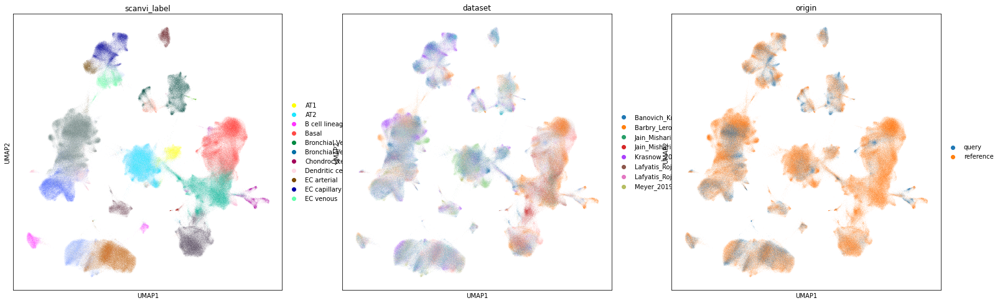

Show plot: Distribution of neighborhood sizes.


/opt/python/lib/python3.8/site-packages/anndata/_core/anndata.py:120: ImplicitModificationWarning: Transforming to str index.
  warnings.warn("Transforming to str index.", ImplicitModificationWarning)
/opt/python/lib/python3.8/site-packages/anndata/_core/anndata.py:801: UserWarning: 
AnnData expects .var.index to contain strings, but got values like:
    ['356C_0h', '356C_12h', '356C_24h', '356C_72h', '368C_0h']

    Inferred to be: categorical

  value_idx = self._prep_dim_index(value.index, attr)


Show plot: log-Fold Changes for healthy_denovo_recalc
Show plot: UMAP neighborhood graph with logFC values.


/opt/python/lib/python3.8/site-packages/anndata/_core/anndata.py:120: ImplicitModificationWarning: Transforming to str index.
  warnings.warn("Transforming to str index.", ImplicitModificationWarning)


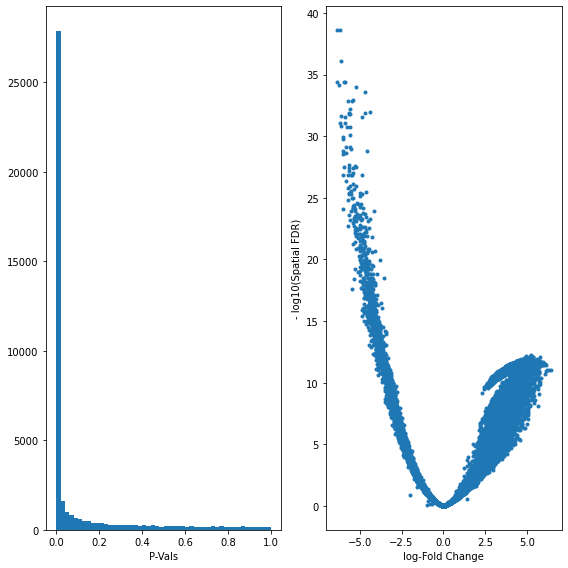

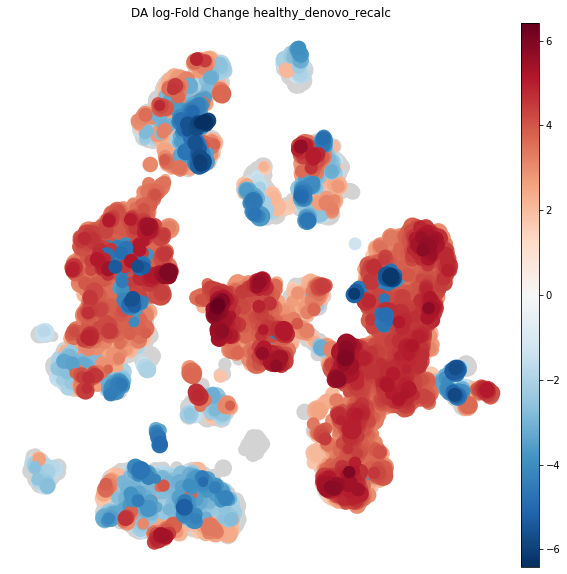

Show plot: Top cell label fraction per neighborhood.


... storing 'nhood_annotation' as categorical


Show plot: logFC values per cell label type grouped neighborhood.


/home/jan.domke/.ch_tmp/ipykernel_272149/3099720966.py:25: RuntimeWarning: invalid value encountered in true_divide
  cells_DA_avg = cells_nh_DA_avg.sum(axis=1).A1/cells_nh_DA.getnnz(axis=1)


Save model...


... storing 'highly_variable_intersection-0' as categorical


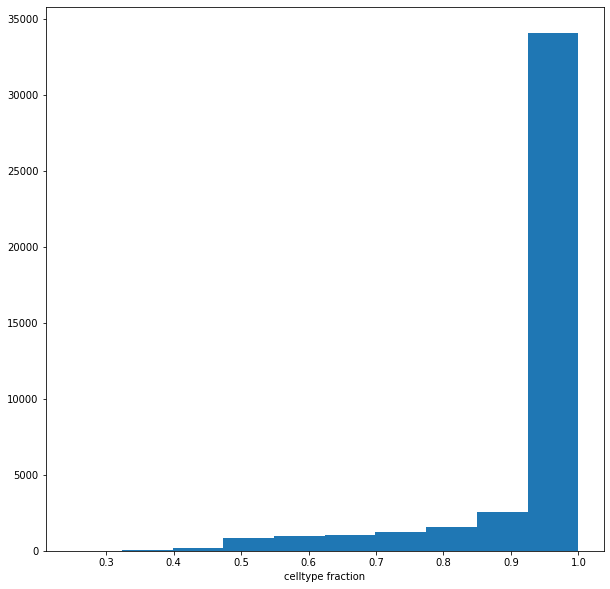

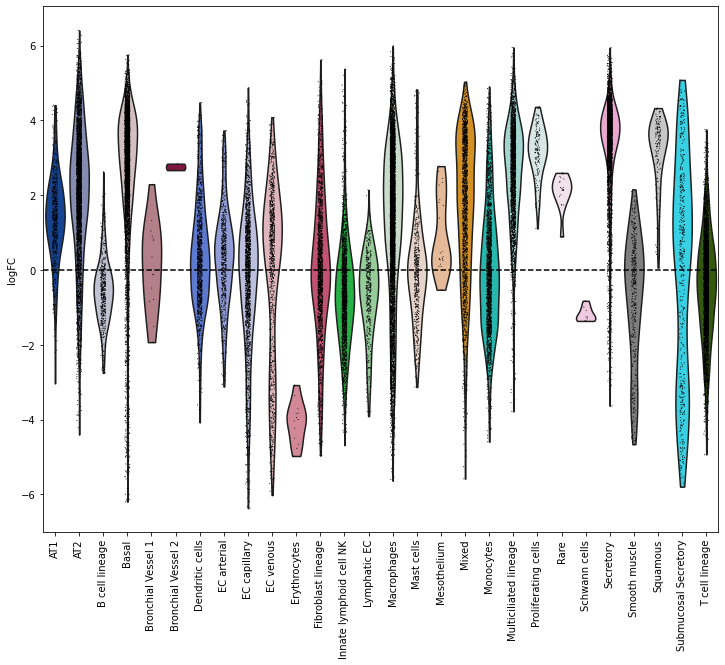

In [ ]:
denovo_recalc = run_milo_workflow(adata = denovo_recalc, name = "healthy_denovo_recalc", embedding = "scANVI", query_dataset= query_dataset_healthy, 
                                  save_loc=save_loc_healthy, k=150)

computing neighbors
    finished: added to `.uns['neighbors']`
    `.obsp['distances']`, distances for each pair of neighbors
    `.obsp['connectivities']`, weighted adjacency matrix (0:18:50)
computing UMAP
    finished: added
    'X_umap', UMAP coordinates (adata.obsm) (0:33:31)


... storing 'origin' as categorical
... storing 'highly_variable_intersection-0' as categorical


Show plot: UMAP of healthy_denovo_ref showing scanvi_label, dataset and origin.


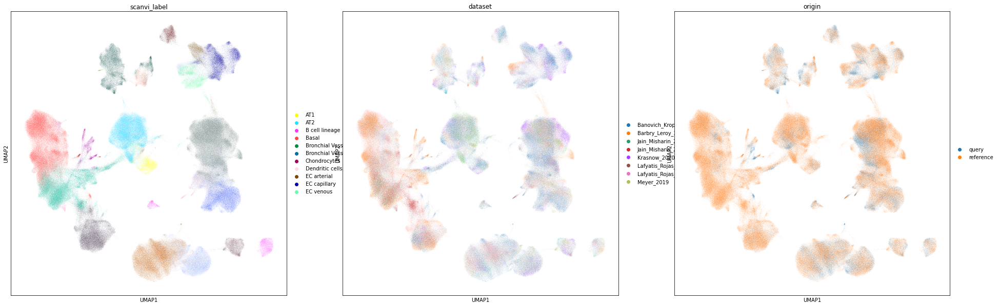

Show plot: Distribution of neighborhood sizes.


/opt/python/lib/python3.8/site-packages/anndata/_core/anndata.py:120: ImplicitModificationWarning: Transforming to str index.
  warnings.warn("Transforming to str index.", ImplicitModificationWarning)
/opt/python/lib/python3.8/site-packages/anndata/_core/anndata.py:801: UserWarning: 
AnnData expects .var.index to contain strings, but got values like:
    ['356C_0h', '356C_12h', '356C_24h', '356C_72h', '368C_0h']

    Inferred to be: categorical

  value_idx = self._prep_dim_index(value.index, attr)


Show plot: log-Fold Changes for healthy_denovo_ref
Show plot: UMAP neighborhood graph with logFC values.


/opt/python/lib/python3.8/site-packages/anndata/_core/anndata.py:120: ImplicitModificationWarning: Transforming to str index.
  warnings.warn("Transforming to str index.", ImplicitModificationWarning)


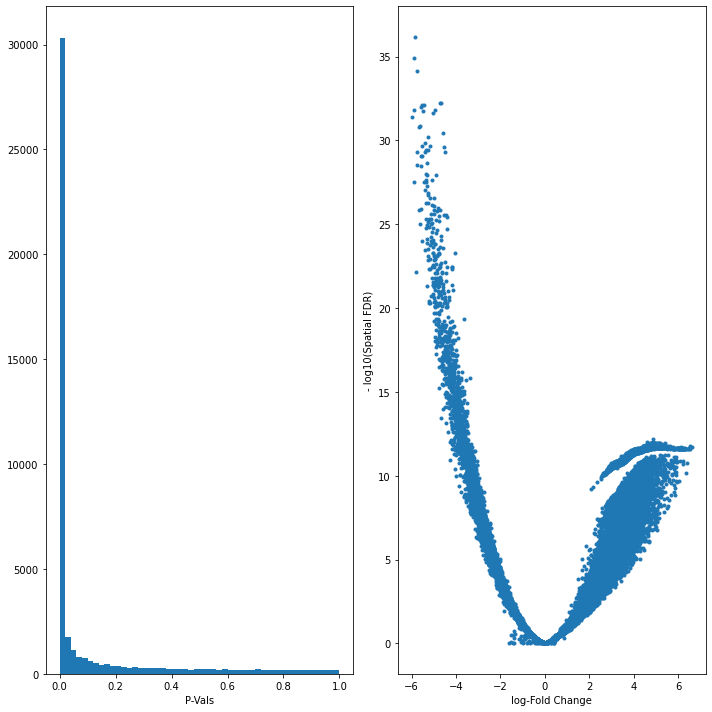

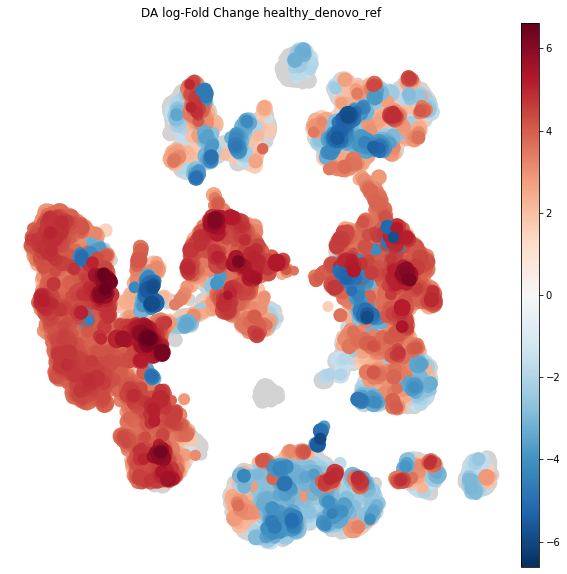

Show plot: Top cell label fraction per neighborhood.


... storing 'nhood_annotation' as categorical


Show plot: logFC values per cell label type grouped neighborhood.


/home/jan.domke/.ch_tmp/ipykernel_272149/3099720966.py:25: RuntimeWarning: invalid value encountered in true_divide
  cells_DA_avg = cells_nh_DA_avg.sum(axis=1).A1/cells_nh_DA.getnnz(axis=1)


Save model...


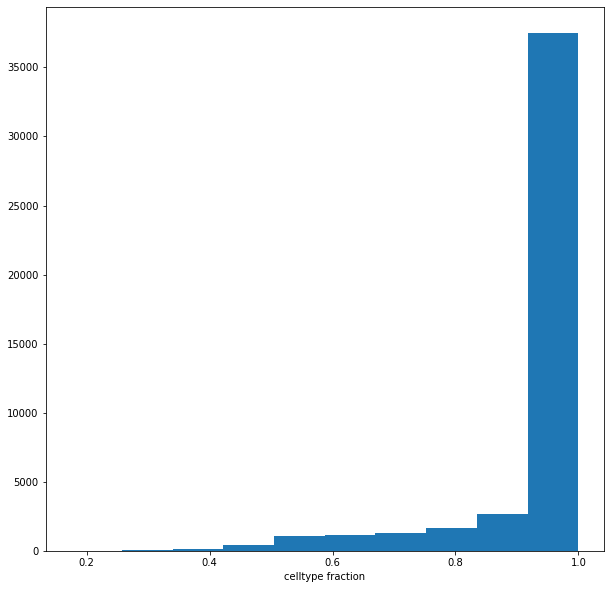

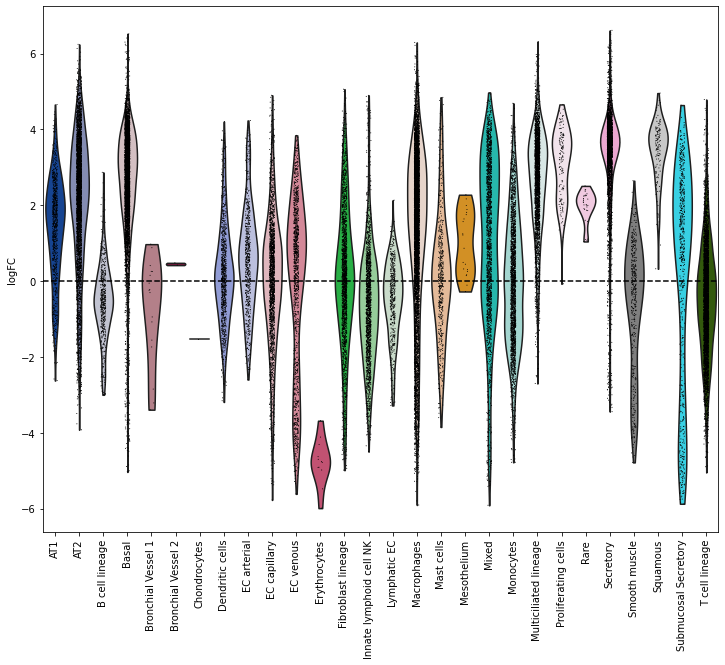

In [20]:
denovo_ref = run_milo_workflow(adata = denovo_ref, name = "healthy_denovo_ref", embedding = "scANVI", query_dataset= query_dataset_healthy, 
                               save_loc=save_loc_healthy, k=150)

computing neighbors
    finished: added to `.uns['neighbors']`
    `.obsp['distances']`, distances for each pair of neighbors
    `.obsp['connectivities']`, weighted adjacency matrix (0:17:48)
computing UMAP
Show plot: Distribution of neighborhood sizes.


/opt/python/lib/python3.8/site-packages/anndata/_core/anndata.py:120: ImplicitModificationWarning: Transforming to str index.
  warnings.warn("Transforming to str index.", ImplicitModificationWarning)
/opt/python/lib/python3.8/site-packages/anndata/_core/anndata.py:801: UserWarning: 
AnnData expects .var.index to contain strings, but got values like:
    ['356C_0h', '356C_12h', '356C_24h', '356C_72h', '368C_0h']

    Inferred to be: categorical

  value_idx = self._prep_dim_index(value.index, attr)


Show plot: log-Fold Changes for healthy_scarches_unlabeled
Show plot: UMAP neighborhood graph with logFC values.


/opt/python/lib/python3.8/site-packages/anndata/_core/anndata.py:120: ImplicitModificationWarning: Transforming to str index.
  warnings.warn("Transforming to str index.", ImplicitModificationWarning)


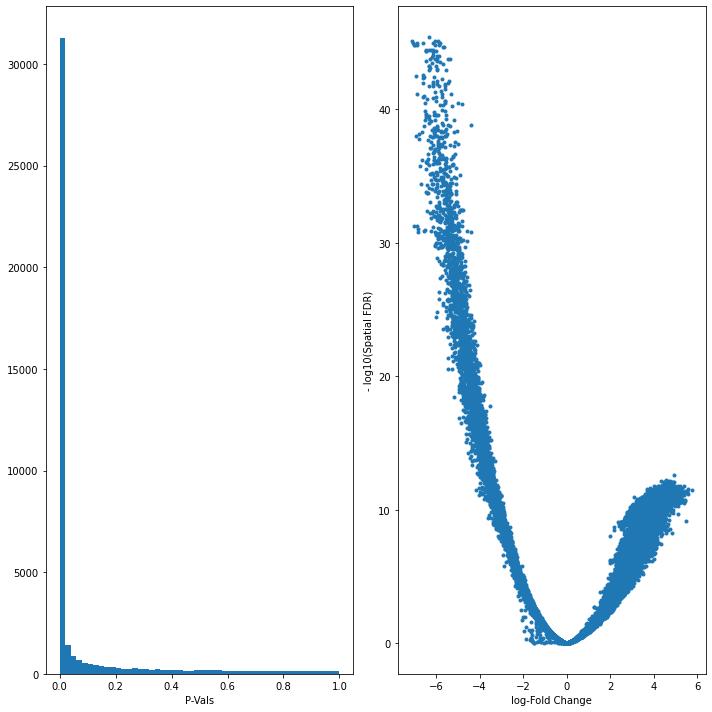

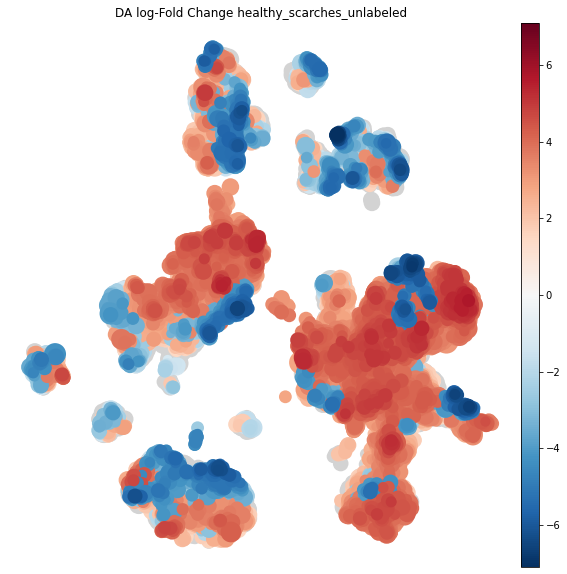

Show plot: Top cell label fraction per neighborhood.


... storing 'nhood_annotation' as categorical


Show plot: logFC values per cell label type grouped neighborhood.


/home/jan.domke/.ch_tmp/ipykernel_272149/3099720966.py:25: RuntimeWarning: invalid value encountered in true_divide
  cells_DA_avg = cells_nh_DA_avg.sum(axis=1).A1/cells_nh_DA.getnnz(axis=1)


Save model...


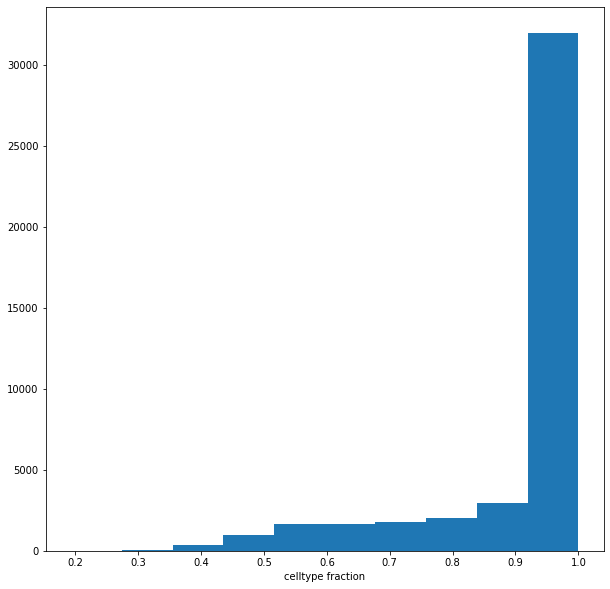

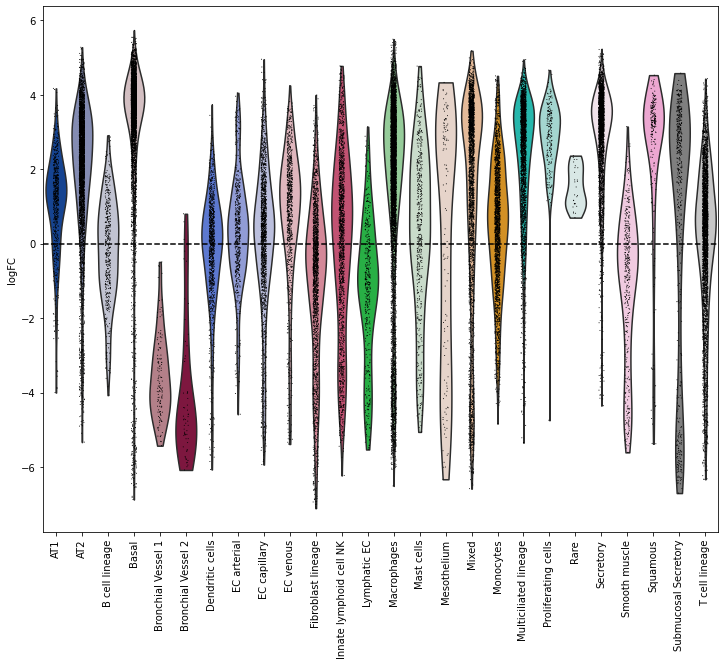

In [21]:
scarches_unlabeled = run_milo_workflow(adata = scarches_unlabeled, name = "healthy_scarches_unlabeled", embedding = "scArches", 
                                       query_dataset= query_dataset_healthy, save_loc=save_loc_healthy, k=150)

computing neighbors
    finished: added to `.uns['neighbors']`
    `.obsp['distances']`, distances for each pair of neighbors
    `.obsp['connectivities']`, weighted adjacency matrix (0:17:51)
computing UMAP
    finished: added
    'X_umap', UMAP coordinates (adata.obsm) (0:32:35)


... storing 'origin' as categorical


Show plot: UMAP of healthy_scarches_labeled showing scanvi_label, dataset and origin.


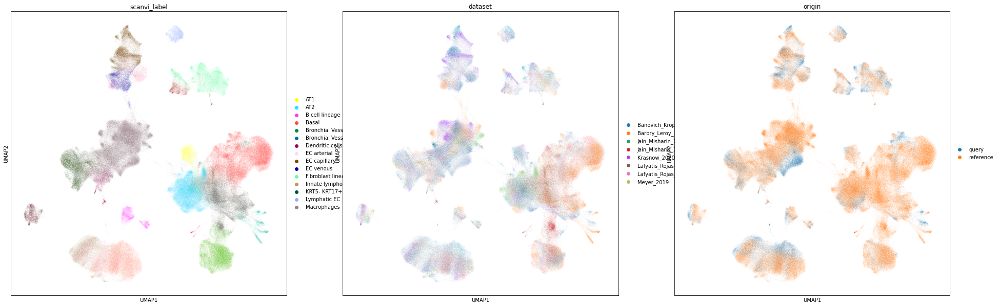

In [ ]:
scarches_labeled = run_milo_workflow(adata = scarches_labeled, name = "healthy_scarches_labeled", embedding = "scArches", 
                                     query_dataset= query_dataset_healthy, save_loc=save_loc_healthy, k=150)

In [ ]:
#Separately save logFC values for k=150
denovo_recalc_logFC_avg = denovo_recalc.obs.logFC_avg
denovo_ref_logFC_avg = denovo_ref.obs.logFC_avg
scarches_unlabeled_logFC_avg = scarches_unlabeled.obs.logFC_avg
scarches_labeled_logFC_avg = scarches_labeled.obs.logFC_avg

denovo_recalc_logFC_avg.to_pickle("/storage/groups/ml01/workspace/jan.domke/Data/Data_Milo/New_higher_k/healthy_denovo_recalc_logFC.h5ad")
denovo_ref_logFC_avg.to_pickle("/storage/groups/ml01/workspace/jan.domke/Data/Data_Milo/New_higher_k/healthy_denovo_ref_logFC.h5ad")
scarches_unlabeled_logFC_avg.to_pickle("/storage/groups/ml01/workspace/jan.domke/Data/Data_Milo/New_higher_k/healthy_scarches_unlabeled_logFC.h5ad")
scarches_labeled_logFC_avg.to_pickle("/storage/groups/ml01/workspace/jan.domke/Data/Data_Milo/New_higher_k/healthy_scarches_labeled_logFC.h5ad")

### 2. Run Milo framework for all models using the IPF data

In [27]:
#Import learned atlases ipf
denovo_recalc = sc.read("/storage/groups/ml01/workspace/jan.domke/Data/Models/IPF/learned_atlas/IPF_atlas_denovo.h5ad")
denovo_ref = sc.read("/storage/groups/ml01/workspace/jan.domke/Data/Models/IPF/learned_atlas/IPF_atlas_denovo_ref_hvg.h5ad")
scarches_unlabeled = sc.read("/storage/groups/ml01/workspace/jan.domke/Data/Models/IPF/learned_atlas/IPF_atlas_scArches_full.h5ad")
scarches_labeled = sc.read("/storage/groups/ml01/workspace/jan.domke/Data/Models/IPF/learned_atlas/IPF_atlas_scArches_labeled_full.h5ad")

computing neighbors
    finished: added to `.uns['neighbors']`
    `.obsp['distances']`, distances for each pair of neighbors
    `.obsp['connectivities']`, weighted adjacency matrix (0:22:35)
computing UMAP
    finished: added
    'X_umap', UMAP coordinates (adata.obsm) (0:46:49)


... storing 'age' as categorical


Show plot: UMAP of ipf_denovo_recalc showing scanvi_label, dataset and origin.


... storing 'origin' as categorical
... storing 'highly_variable_intersection-0' as categorical


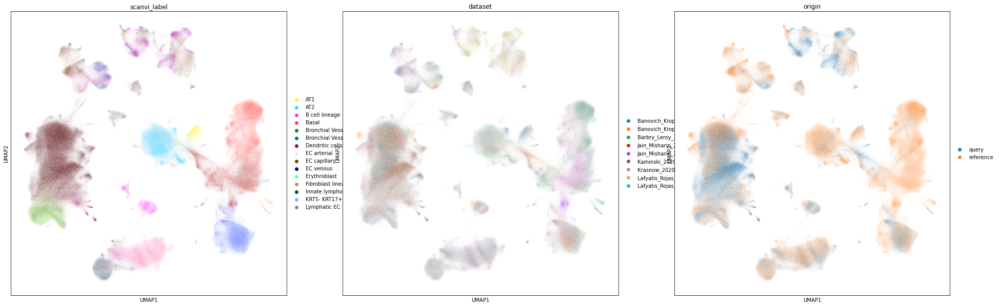

Show plot: Distribution of neighborhood sizes.


/opt/python/lib/python3.8/site-packages/anndata/_core/anndata.py:120: ImplicitModificationWarning: Transforming to str index.
  warnings.warn("Transforming to str index.", ImplicitModificationWarning)
/opt/python/lib/python3.8/site-packages/anndata/_core/anndata.py:801: UserWarning: 
AnnData expects .var.index to contain strings, but got values like:
    ['001C', '002C', '003C', '010I', '021I']

    Inferred to be: categorical

  value_idx = self._prep_dim_index(value.index, attr)


Show plot: log-Fold Changes for ipf_denovo_recalc
Show plot: UMAP neighborhood graph with logFC values.


/opt/python/lib/python3.8/site-packages/anndata/_core/anndata.py:120: ImplicitModificationWarning: Transforming to str index.
  warnings.warn("Transforming to str index.", ImplicitModificationWarning)


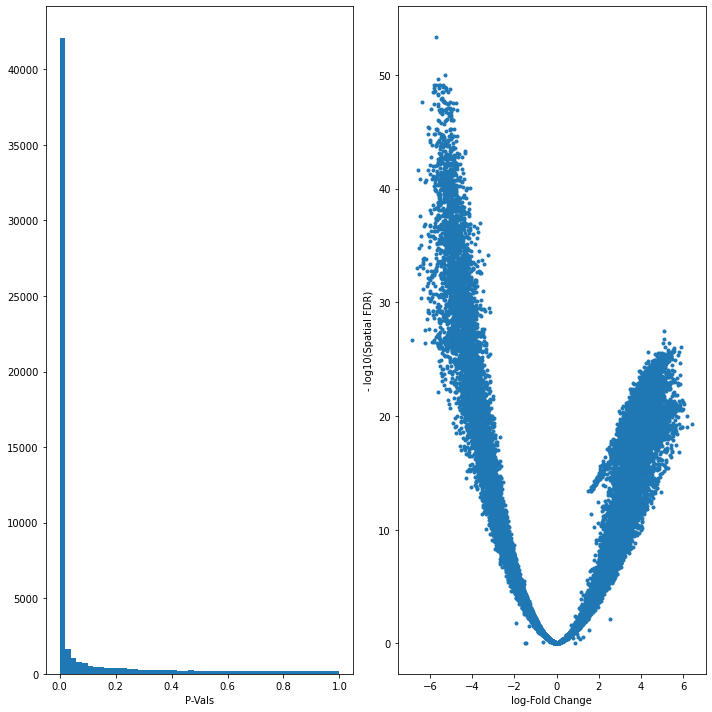

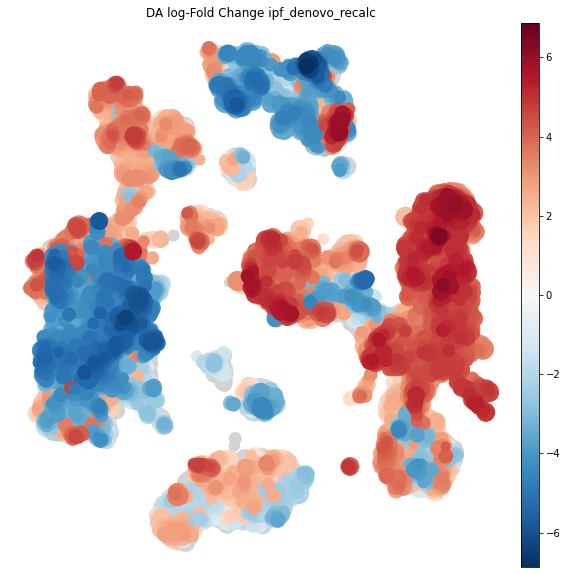

Show plot: Top cell label fraction per neighborhood.


... storing 'nhood_annotation' as categorical


Show plot: logFC values per cell label type grouped neighborhood.


/home/jan.domke/.ch_tmp/ipykernel_322260/3099720966.py:25: RuntimeWarning: invalid value encountered in true_divide
  cells_DA_avg = cells_nh_DA_avg.sum(axis=1).A1/cells_nh_DA.getnnz(axis=1)


Save model...


... storing 'highly_variable_intersection-0' as categorical


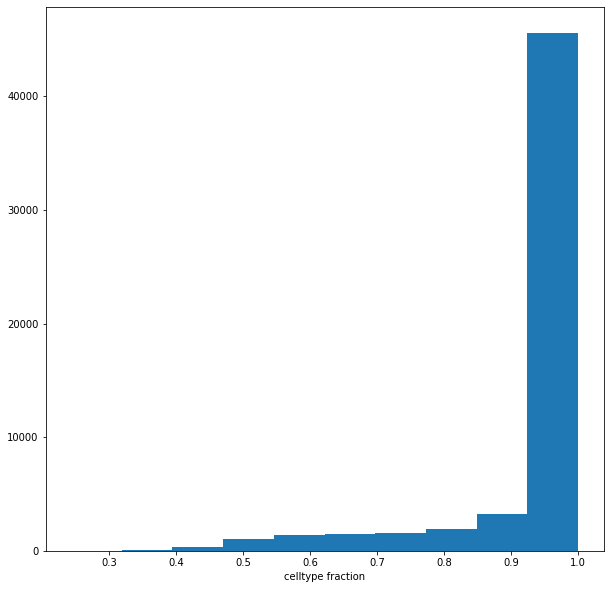

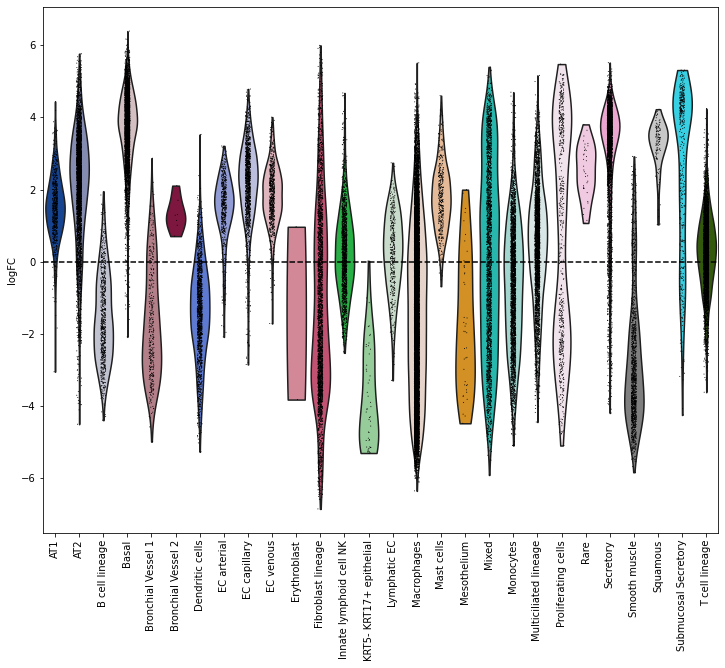

In [28]:
denovo_recalc = run_milo_workflow(adata = denovo_recalc, name = "ipf_denovo_recalc", embedding = "scANVI", query_dataset= query_dataset_ipf, 
                                  save_loc=save_loc_ipf, k=150)

computing neighbors
    finished: added to `.uns['neighbors']`
    `.obsp['distances']`, distances for each pair of neighbors
    `.obsp['connectivities']`, weighted adjacency matrix (0:24:09)
computing UMAP
    finished: added
    'X_umap', UMAP coordinates (adata.obsm) (1:05:48)


... storing 'age' as categorical


Show plot: UMAP of ipf_denovo_ref showing scanvi_label, dataset and origin.


... storing 'origin' as categorical
... storing 'highly_variable_intersection-0' as categorical


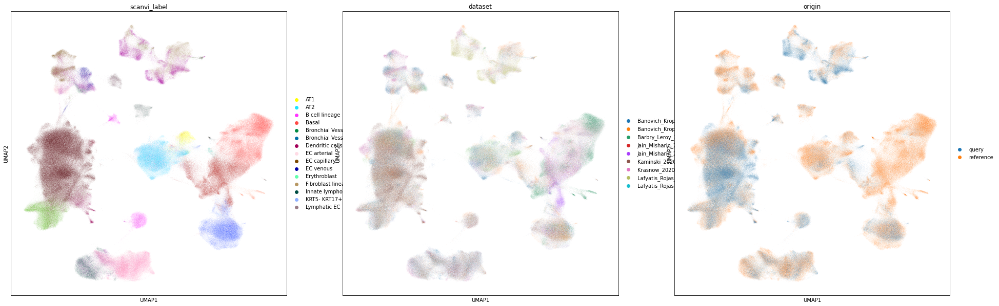

Show plot: Distribution of neighborhood sizes.


/opt/python/lib/python3.8/site-packages/anndata/_core/anndata.py:120: ImplicitModificationWarning: Transforming to str index.
  warnings.warn("Transforming to str index.", ImplicitModificationWarning)
/opt/python/lib/python3.8/site-packages/anndata/_core/anndata.py:801: UserWarning: 
AnnData expects .var.index to contain strings, but got values like:
    ['001C', '002C', '003C', '010I', '021I']

    Inferred to be: categorical

  value_idx = self._prep_dim_index(value.index, attr)


Show plot: log-Fold Changes for ipf_denovo_ref
Show plot: UMAP neighborhood graph with logFC values.


/opt/python/lib/python3.8/site-packages/anndata/_core/anndata.py:120: ImplicitModificationWarning: Transforming to str index.
  warnings.warn("Transforming to str index.", ImplicitModificationWarning)


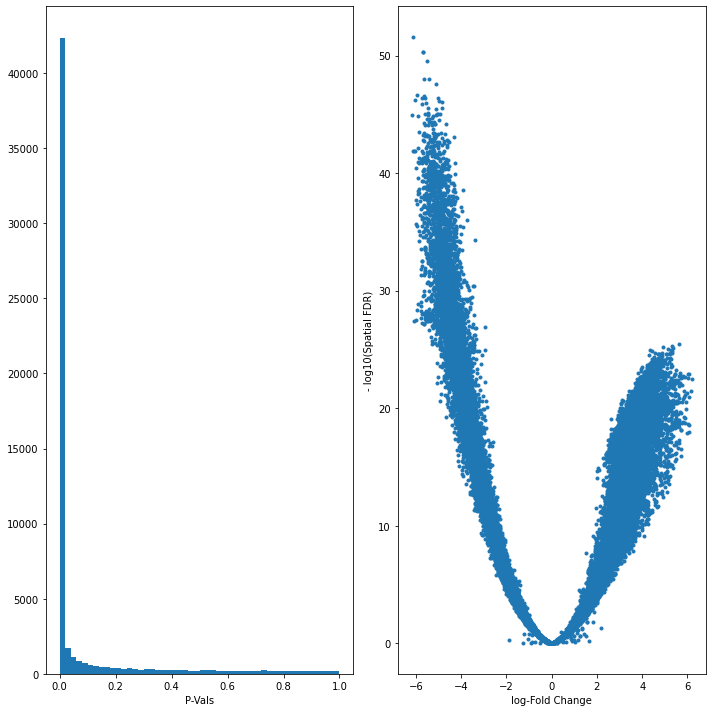

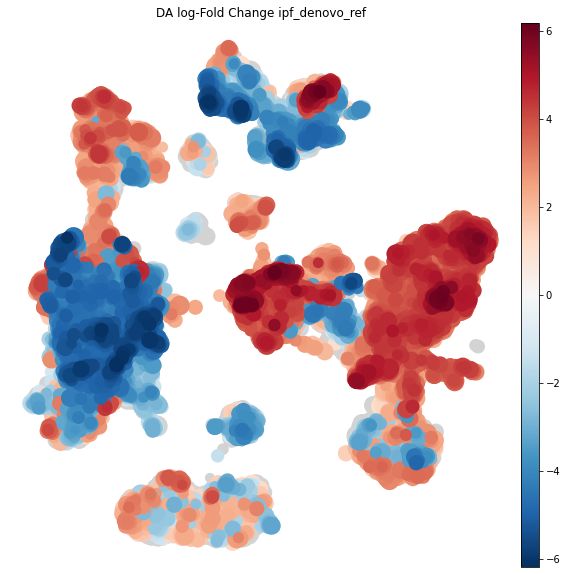

Show plot: Top cell label fraction per neighborhood.
Show plot: logFC values per cell label type grouped neighborhood.


... storing 'nhood_annotation' as categorical
/home/jan.domke/.ch_tmp/ipykernel_322260/3099720966.py:25: RuntimeWarning: invalid value encountered in true_divide
  cells_DA_avg = cells_nh_DA_avg.sum(axis=1).A1/cells_nh_DA.getnnz(axis=1)


Save model...


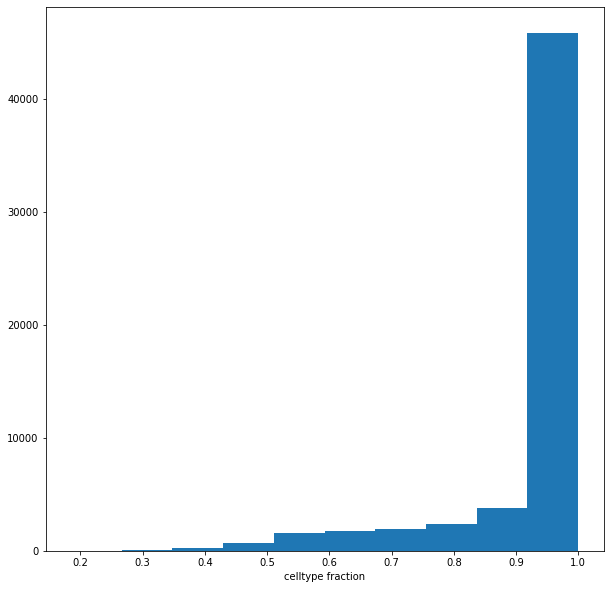

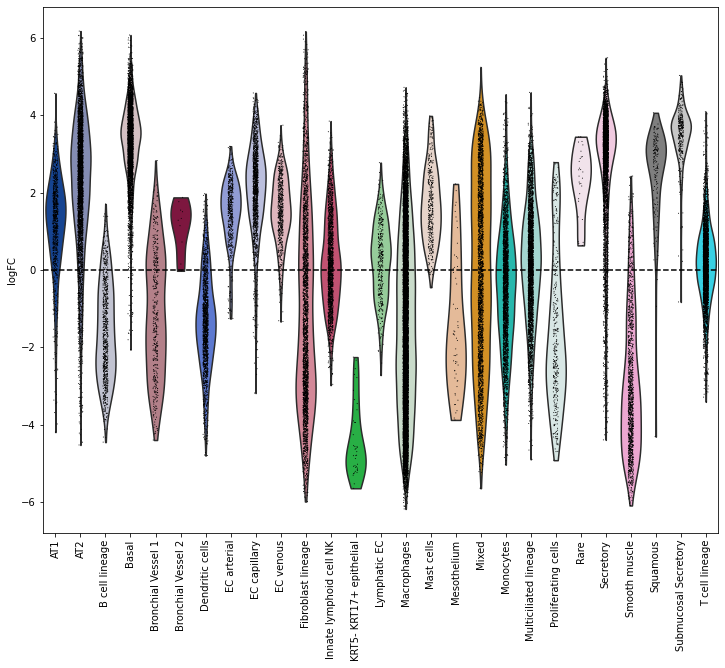

In [11]:
denovo_ref = run_milo_workflow(adata = denovo_ref, name = "ipf_denovo_ref", embedding = "scANVI", query_dataset= query_dataset_ipf, 
                               save_loc=save_loc_ipf, k=150)

computing neighbors
    finished: added to `.uns['neighbors']`
    `.obsp['distances']`, distances for each pair of neighbors
    `.obsp['connectivities']`, weighted adjacency matrix (0:23:33)
computing UMAP
    finished: added
    'X_umap', UMAP coordinates (adata.obsm) (0:56:01)


... storing 'age' as categorical


Show plot: UMAP of ipf_scarches_unlabeled showing scanvi_label, dataset and origin.


... storing 'origin' as categorical


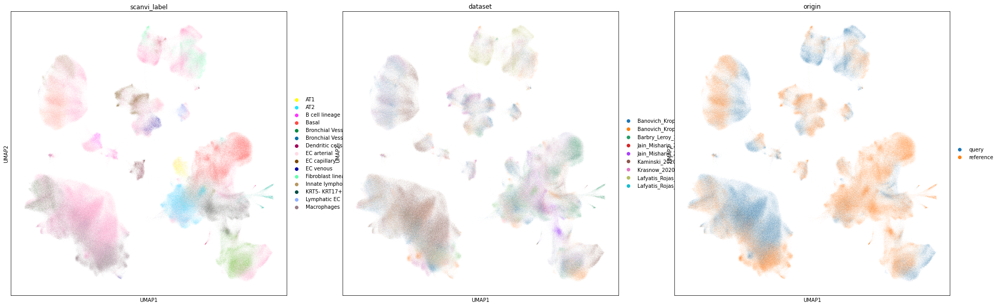

In [ ]:
scarches_unlabeled = run_milo_workflow(adata = scarches_unlabeled, name = "ipf_scarches_unlabeled", embedding = "scArches", query_dataset= query_dataset_ipf,
                                       save_loc=save_loc_ipf, k=150)

computing neighbors
    finished: added to `.uns['neighbors']`
    `.obsp['distances']`, distances for each pair of neighbors
    `.obsp['connectivities']`, weighted adjacency matrix (0:23:40)
computing UMAP
    finished: added
    'X_umap', UMAP coordinates (adata.obsm) (0:49:05)


... storing 'age' as categorical


Show plot: UMAP of ipf_scarches_labeled showing scanvi_label, dataset and origin.


... storing 'origin' as categorical


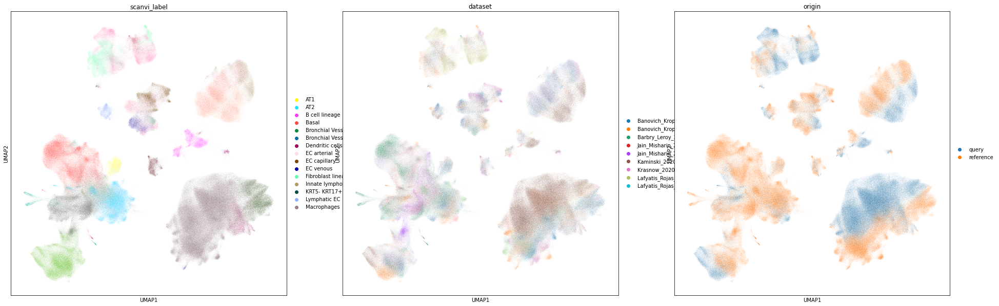

Show plot: Distribution of neighborhood sizes.


/opt/python/lib/python3.8/site-packages/anndata/_core/anndata.py:120: ImplicitModificationWarning: Transforming to str index.
  warnings.warn("Transforming to str index.", ImplicitModificationWarning)
/opt/python/lib/python3.8/site-packages/anndata/_core/anndata.py:801: UserWarning: 
AnnData expects .var.index to contain strings, but got values like:
    ['001C', '002C', '003C', '010I', '021I']

    Inferred to be: categorical

  value_idx = self._prep_dim_index(value.index, attr)


Show plot: log-Fold Changes for ipf_scarches_labeled
Show plot: UMAP neighborhood graph with logFC values.


/opt/python/lib/python3.8/site-packages/anndata/_core/anndata.py:120: ImplicitModificationWarning: Transforming to str index.
  warnings.warn("Transforming to str index.", ImplicitModificationWarning)


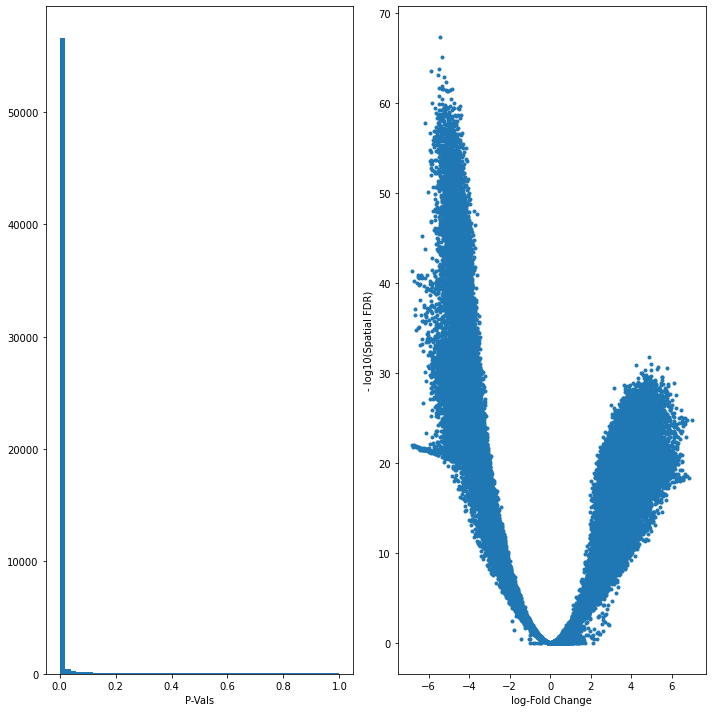

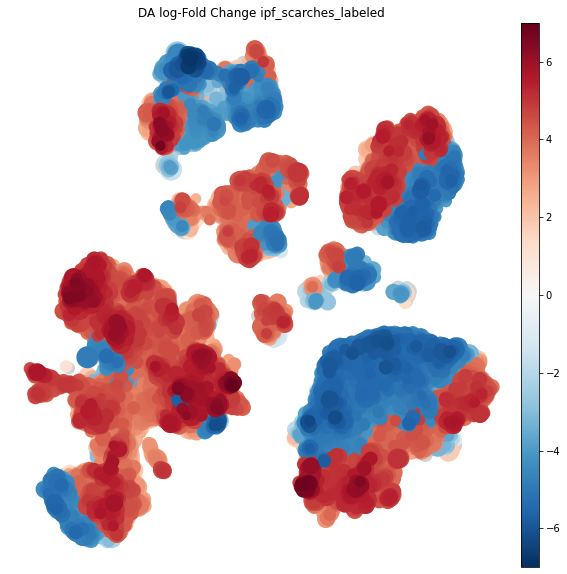

Show plot: Top cell label fraction per neighborhood.


... storing 'nhood_annotation' as categorical


Show plot: logFC values per cell label type grouped neighborhood.


/home/jan.domke/.ch_tmp/ipykernel_322260/3099720966.py:25: RuntimeWarning: invalid value encountered in true_divide
  cells_DA_avg = cells_nh_DA_avg.sum(axis=1).A1/cells_nh_DA.getnnz(axis=1)


Save model...


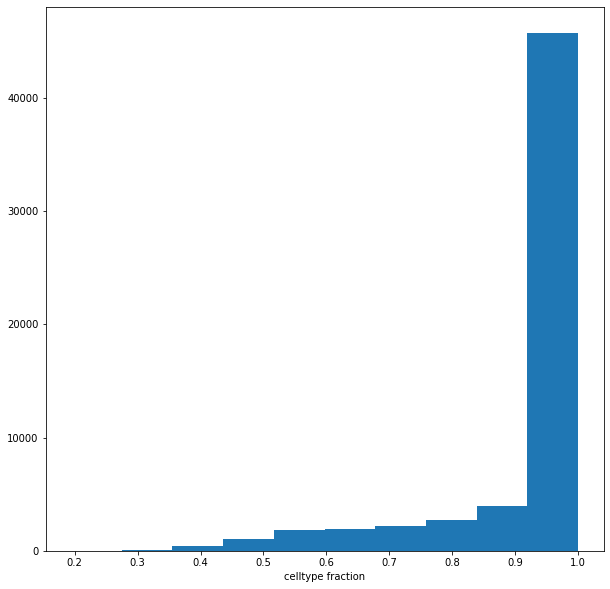

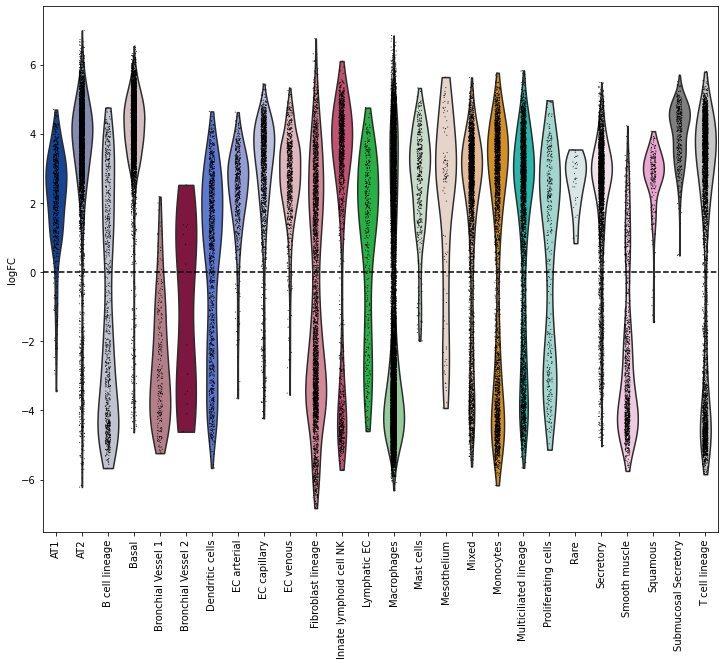

In [13]:
scarches_labeled = run_milo_workflow(adata = scarches_labeled, name = "ipf_scarches_labeled", embedding = "scArches",
                                     query_dataset= query_dataset_ipf, save_loc=save_loc_ipf, k=150)

In [ ]:
#Separately save logFC values for k=150
denovo_recalc_logFC_avg = denovo_recalc.obs.logFC_avg
denovo_ref_logFC_avg = denovo_ref.obs.logFC_avg
scarches_unlabeled_logFC_avg = scarches_unlabeled.obs.logFC_avg
scarches_labeled_logFC_avg = scarches_labeled.obs.logFC_avg

denovo_recalc_logFC_avg.to_pickle("/storage/groups/ml01/workspace/jan.domke/Data/Data_Milo/New_higher_k/ipf_denovo_recalc_logFC.h5ad")
denovo_ref_logFC_avg.to_pickle("/storage/groups/ml01/workspace/jan.domke/Data/Data_Milo/New_higher_k/ipf_denovo_ref_logFC.h5ad")
scarches_unlabeled_logFC_avg.to_pickle("/storage/groups/ml01/workspace/jan.domke/Data/Data_Milo/New_higher_k/ipf_scarches_unlabeled_logFC.h5ad")
scarches_labeled_logFC_avg.to_pickle("/storage/groups/ml01/workspace/jan.domke/Data/Data_Milo/New_higher_k/ipf_scarches_labeled_logFC.h5ad")

### 3. Run Milo framework for all models using the nucleus data

In [15]:
#Import learned atlases ipf
denovo_recalc = sc.read("/storage/groups/ml01/workspace/jan.domke/Data/Models/nucleus/learned_atlas/nucleus_atlas_denovo.h5ad")
denovo_ref = sc.read("/storage/groups/ml01/workspace/jan.domke/Data/Models/nucleus/learned_atlas/nucleus_atlas_denovo_ref_hvg.h5ad")
scarches_unlabeled = sc.read("/storage/groups/ml01/workspace/jan.domke/Data/Models/nucleus/learned_atlas/nucleus_atlas_scArches_full.h5ad")
scarches_labeled = sc.read("/storage/groups/ml01/workspace/jan.domke/Data/Models/nucleus/learned_atlas/nucleus_atlas_scArches_labeled_full.h5ad")

In [7]:
scarches_labeled = sc.read("/storage/groups/ml01/workspace/jan.domke/Data/Models/nucleus/learned_atlas/nucleus_atlas_scArches_labeled_full_II.h5ad")

computing neighbors
    finished: added to `.uns['neighbors']`
    `.obsp['distances']`, distances for each pair of neighbors
    `.obsp['connectivities']`, weighted adjacency matrix (0:18:24)
computing UMAP
    finished: added
    'X_umap', UMAP coordinates (adata.obsm) (0:36:19)


... storing 'age' as categorical
... storing 'origin' as categorical
... storing 'highly_variable_intersection-0' as categorical


Show plot: UMAP of nucleus_denovo_recalc showing scanvi_label, dataset and origin.


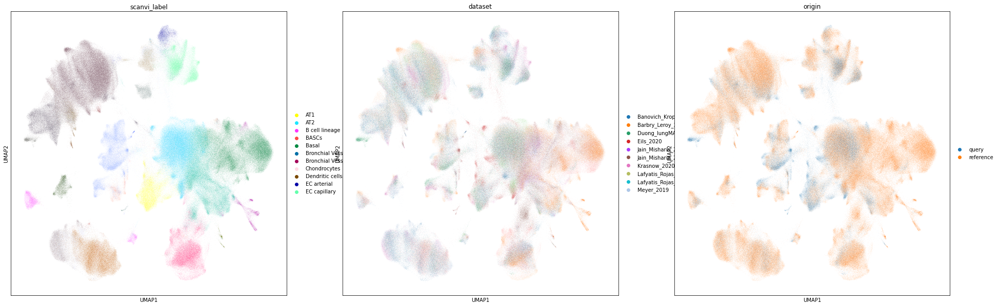

Show plot: Distribution of neighborhood sizes.


/opt/python/lib/python3.8/site-packages/anndata/_core/anndata.py:120: ImplicitModificationWarning: Transforming to str index.
  warnings.warn("Transforming to str index.", ImplicitModificationWarning)
/opt/python/lib/python3.8/site-packages/anndata/_core/anndata.py:801: UserWarning: 
AnnData expects .var.index to contain strings, but got values like:
    ['1A1DFBng', '9JQK55ng', '16E0F2ng', '101CV0ng', '356C_0h']

    Inferred to be: categorical

  value_idx = self._prep_dim_index(value.index, attr)


Show plot: log-Fold Changes for nucleus_denovo_recalc
Show plot: UMAP neighborhood graph with logFC values.


/opt/python/lib/python3.8/site-packages/anndata/_core/anndata.py:120: ImplicitModificationWarning: Transforming to str index.
  warnings.warn("Transforming to str index.", ImplicitModificationWarning)


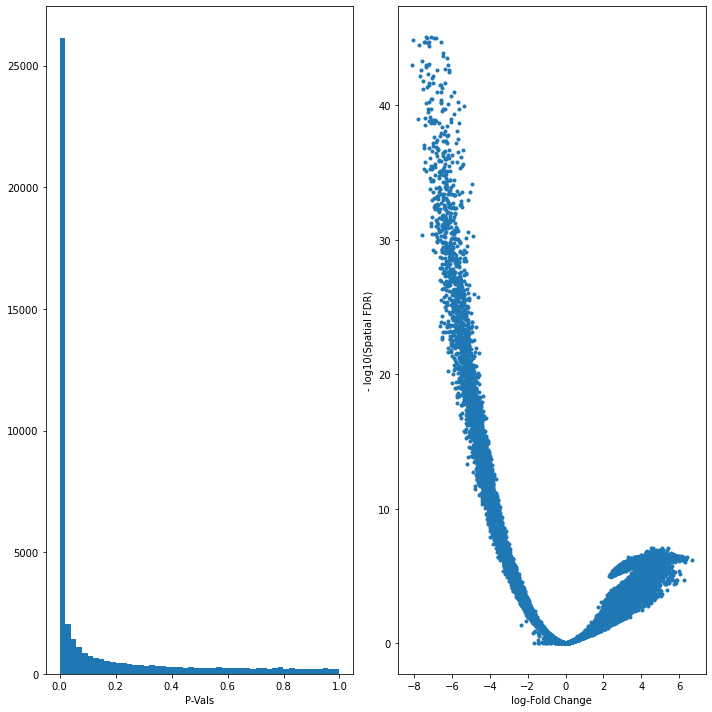

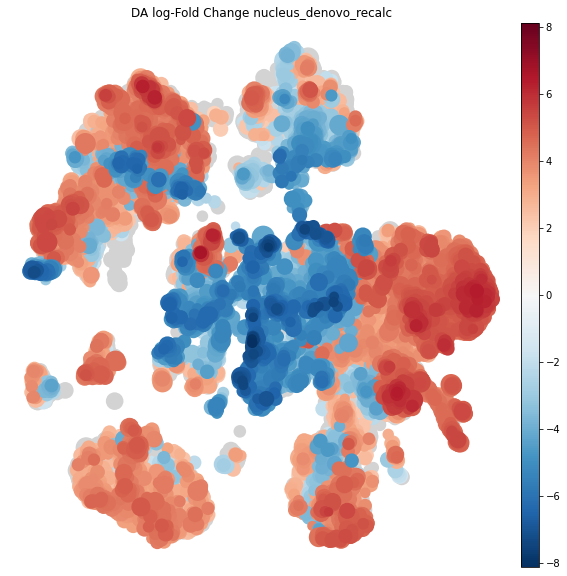

Show plot: Top cell label fraction per neighborhood.


... storing 'nhood_annotation' as categorical


Show plot: logFC values per cell label type grouped neighborhood.


/home/jan.domke/.ch_tmp/ipykernel_322260/3099720966.py:25: RuntimeWarning: invalid value encountered in true_divide
  cells_DA_avg = cells_nh_DA_avg.sum(axis=1).A1/cells_nh_DA.getnnz(axis=1)


Save model...


... storing 'highly_variable_intersection-0' as categorical


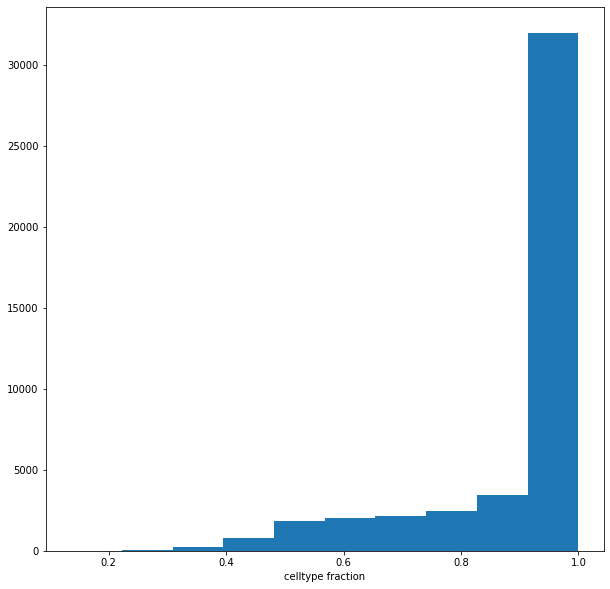

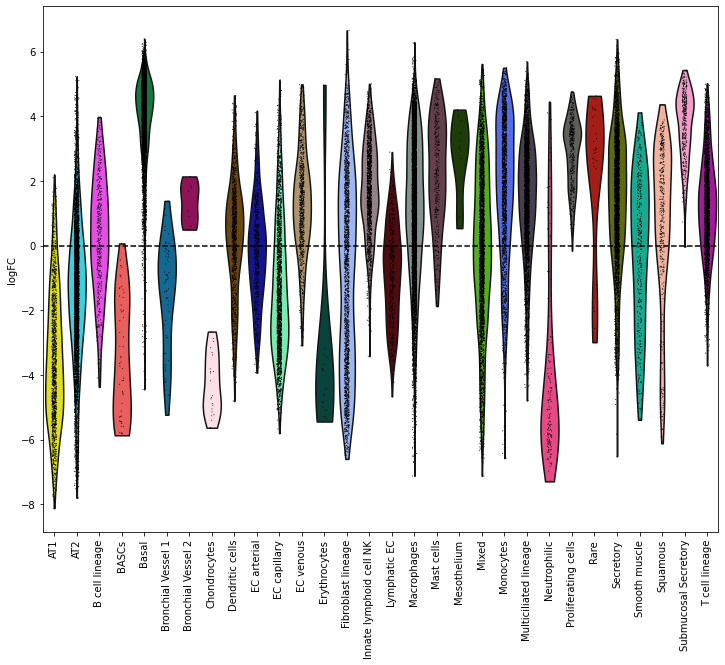

In [16]:
denovo_recalc = run_milo_workflow(adata = denovo_recalc, name = "nucleus_denovo_recalc", embedding = "scANVI",
                                  query_dataset= query_dataset_nucleus, save_loc=save_loc_nucleus, k=150)

computing neighbors
    finished: added to `.uns['neighbors']`
    `.obsp['distances']`, distances for each pair of neighbors
    `.obsp['connectivities']`, weighted adjacency matrix (0:18:11)
computing UMAP
    finished: added
    'X_umap', UMAP coordinates (adata.obsm) (0:32:12)


... storing 'age' as categorical
... storing 'origin' as categorical
... storing 'highly_variable_intersection-0' as categorical


Show plot: UMAP of nucleus_denovo_ref showing scanvi_label, dataset and origin.


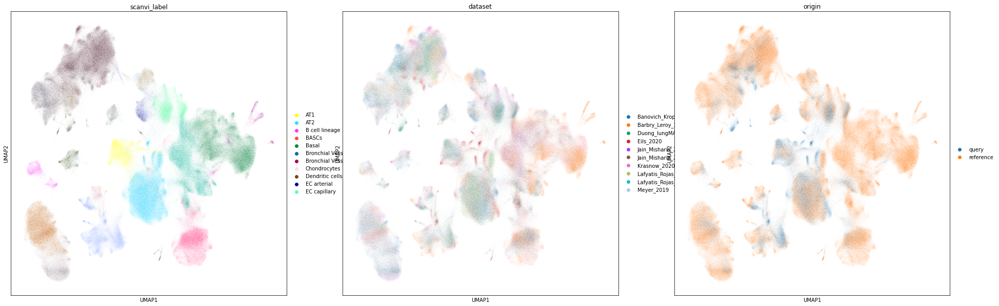

Show plot: Distribution of neighborhood sizes.


/opt/python/lib/python3.8/site-packages/anndata/_core/anndata.py:120: ImplicitModificationWarning: Transforming to str index.
  warnings.warn("Transforming to str index.", ImplicitModificationWarning)
/opt/python/lib/python3.8/site-packages/anndata/_core/anndata.py:801: UserWarning: 
AnnData expects .var.index to contain strings, but got values like:
    ['1A1DFBng', '9JQK55ng', '16E0F2ng', '101CV0ng', '356C_0h']

    Inferred to be: categorical

  value_idx = self._prep_dim_index(value.index, attr)


Show plot: log-Fold Changes for nucleus_denovo_ref
Show plot: UMAP neighborhood graph with logFC values.


/opt/python/lib/python3.8/site-packages/anndata/_core/anndata.py:120: ImplicitModificationWarning: Transforming to str index.
  warnings.warn("Transforming to str index.", ImplicitModificationWarning)


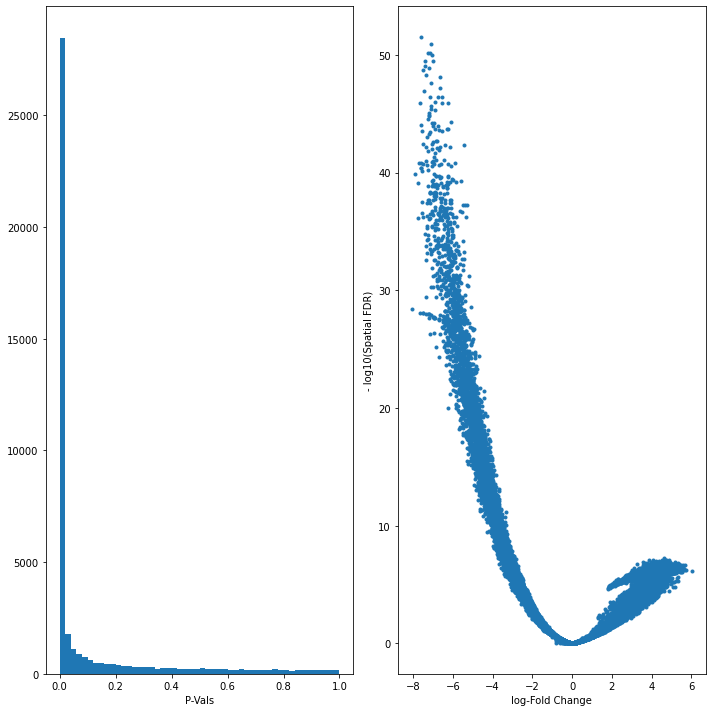

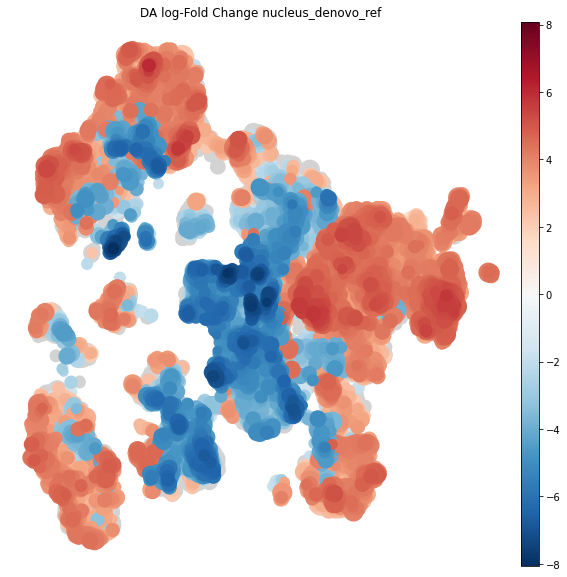

Show plot: Top cell label fraction per neighborhood.
Show plot: logFC values per cell label type grouped neighborhood.


... storing 'nhood_annotation' as categorical
/home/jan.domke/.ch_tmp/ipykernel_322260/3099720966.py:25: RuntimeWarning: invalid value encountered in true_divide
  cells_DA_avg = cells_nh_DA_avg.sum(axis=1).A1/cells_nh_DA.getnnz(axis=1)


Save model...


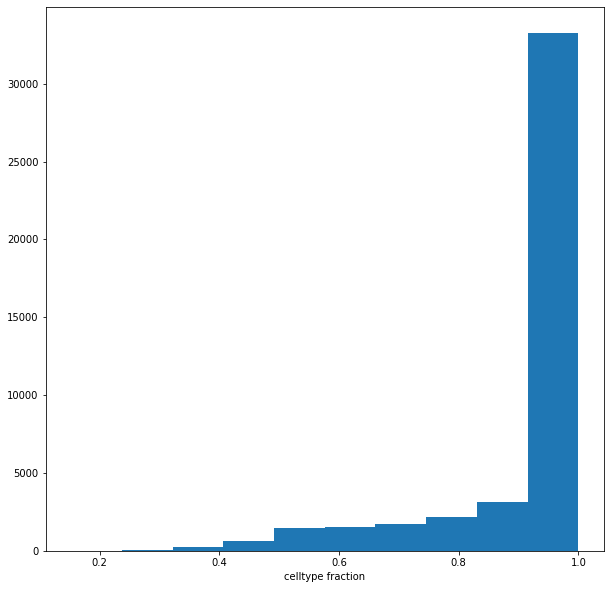

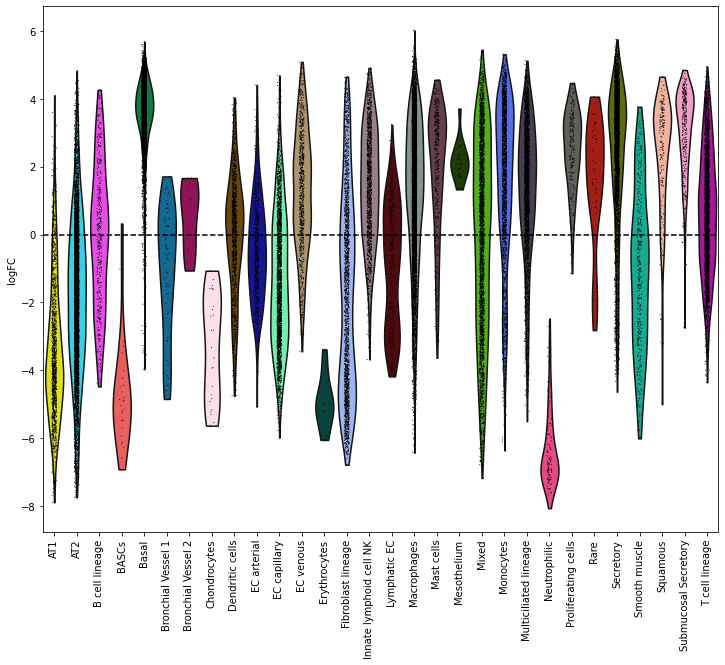

In [17]:
denovo_ref = run_milo_workflow(adata = denovo_ref, name = "nucleus_denovo_ref", embedding = "scANVI",
                               query_dataset= query_dataset_nucleus, save_loc=save_loc_nucleus, k=150)

computing neighbors
    finished: added to `.uns['neighbors']`
    `.obsp['distances']`, distances for each pair of neighbors
    `.obsp['connectivities']`, weighted adjacency matrix (0:18:15)
computing UMAP
    finished: added
    'X_umap', UMAP coordinates (adata.obsm) (0:31:46)


... storing 'age' as categorical
... storing 'origin' as categorical


Show plot: UMAP of nucleus_scarches_unlabeled showing scanvi_label, dataset and origin.


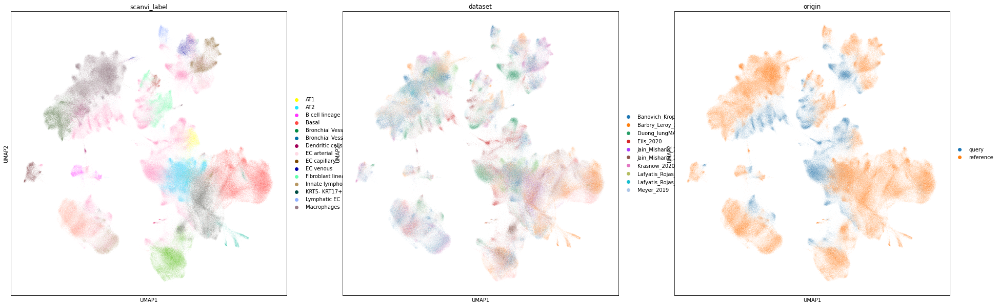

Show plot: Distribution of neighborhood sizes.


/opt/python/lib/python3.8/site-packages/anndata/_core/anndata.py:120: ImplicitModificationWarning: Transforming to str index.
  warnings.warn("Transforming to str index.", ImplicitModificationWarning)
/opt/python/lib/python3.8/site-packages/anndata/_core/anndata.py:801: UserWarning: 
AnnData expects .var.index to contain strings, but got values like:
    ['1A1DFBng', '9JQK55ng', '16E0F2ng', '101CV0ng', '356C_0h']

    Inferred to be: categorical

  value_idx = self._prep_dim_index(value.index, attr)


Show plot: log-Fold Changes for nucleus_scarches_unlabeled
Show plot: UMAP neighborhood graph with logFC values.


/opt/python/lib/python3.8/site-packages/anndata/_core/anndata.py:120: ImplicitModificationWarning: Transforming to str index.
  warnings.warn("Transforming to str index.", ImplicitModificationWarning)


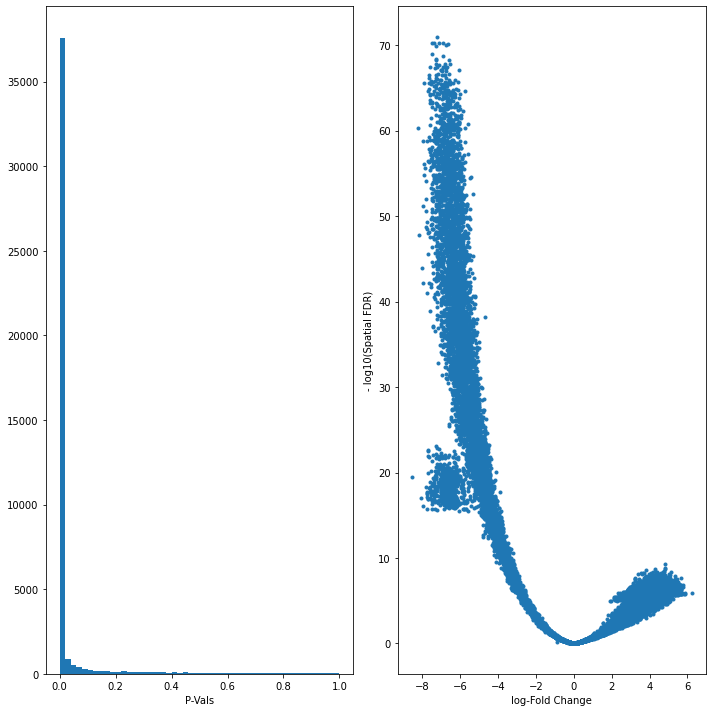

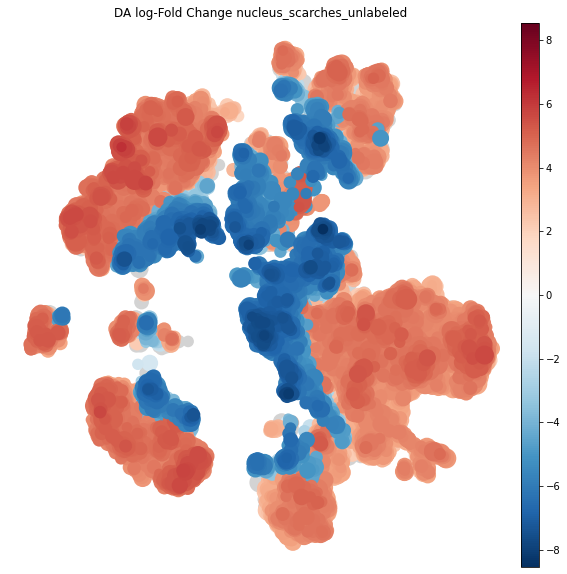

Show plot: Top cell label fraction per neighborhood.
Show plot: logFC values per cell label type grouped neighborhood.


... storing 'nhood_annotation' as categorical
/home/jan.domke/.ch_tmp/ipykernel_322260/3099720966.py:25: RuntimeWarning: invalid value encountered in true_divide
  cells_DA_avg = cells_nh_DA_avg.sum(axis=1).A1/cells_nh_DA.getnnz(axis=1)


Save model...


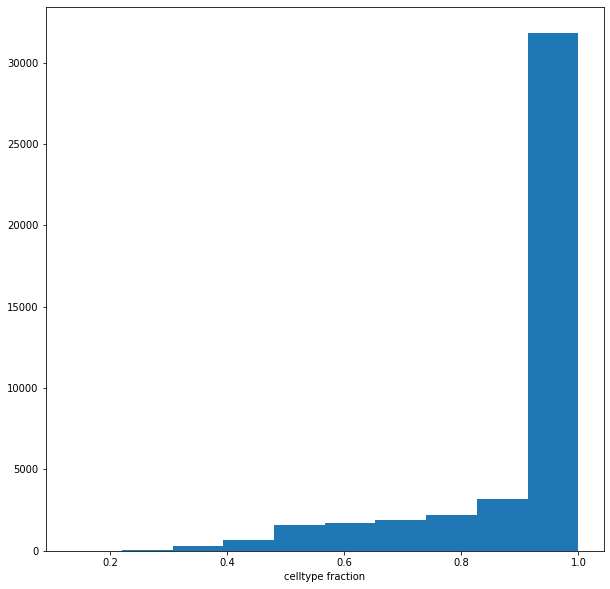

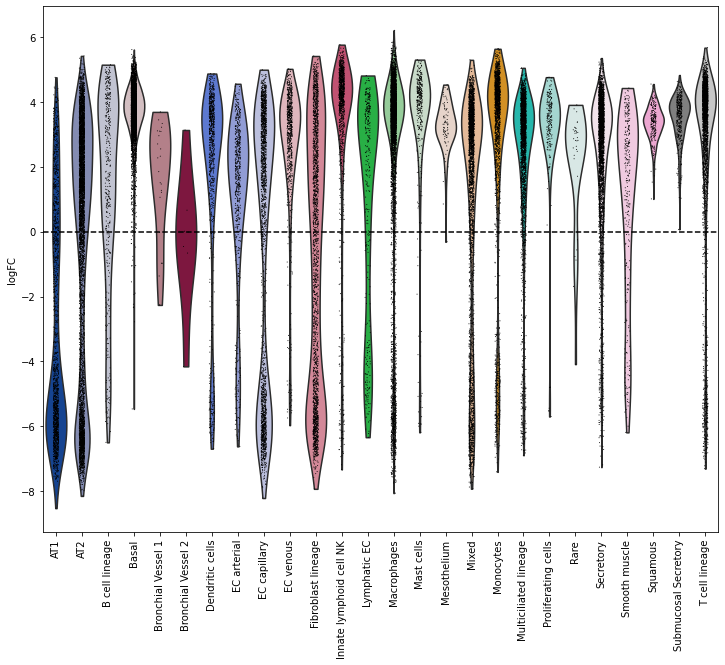

In [18]:
scarches_unlabeled = run_milo_workflow(adata = scarches_unlabeled, name = "nucleus_scarches_unlabeled", embedding = "scArches",
                                       query_dataset= query_dataset_nucleus, save_loc=save_loc_nucleus, k=150)

computing neighbors


2022-02-27 14:25:56.346548: W tensorflow/stream_executor/platform/default/dso_loader.cc:64] Could not load dynamic library 'libcudart.so.11.0'; dlerror: libcudart.so.11.0: cannot open shared object file: No such file or directory; LD_LIBRARY_PATH: /opt/R/lib/R/lib
2022-02-27 14:25:56.346578: I tensorflow/stream_executor/cuda/cudart_stub.cc:29] Ignore above cudart dlerror if you do not have a GPU set up on your machine.


    finished: added to `.uns['neighbors']`
    `.obsp['distances']`, distances for each pair of neighbors
    `.obsp['connectivities']`, weighted adjacency matrix (0:19:00)
computing UMAP
    finished: added
    'X_umap', UMAP coordinates (adata.obsm) (0:33:49)
Show plot: UMAP of nucleus_scarches_labeled showing scanvi_label, dataset and condition.


/opt/python/lib/python3.8/site-packages/anndata/_core/anndata.py:1228: FutureWarning: The `inplace` parameter in pandas.Categorical.reorder_categories is deprecated and will be removed in a future version. Reordering categories will always return a new Categorical object.
  c.reorder_categories(natsorted(c.categories), inplace=True)
... storing 'age' as categorical
/opt/python/lib/python3.8/site-packages/anndata/_core/anndata.py:1228: FutureWarning: The `inplace` parameter in pandas.Categorical.reorder_categories is deprecated and will be removed in a future version. Reordering categories will always return a new Categorical object.
  c.reorder_categories(natsorted(c.categories), inplace=True)
... storing 'condition_milo' as categorical


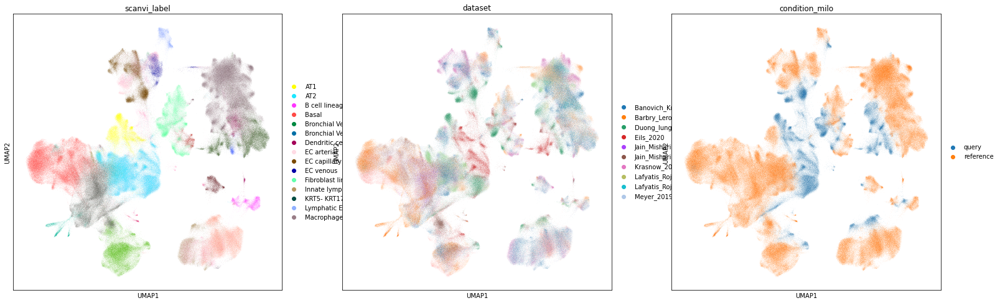

Show plot: Distribution of neighborhood sizes.


/opt/python/lib/python3.8/site-packages/anndata/_core/anndata.py:120: ImplicitModificationWarning: Transforming to str index.
  warnings.warn("Transforming to str index.", ImplicitModificationWarning)
/opt/python/lib/python3.8/site-packages/anndata/_core/anndata.py:801: UserWarning: 
AnnData expects .var.index to contain strings, but got values like:
    ['1A1DFBng', '9JQK55ng', '16E0F2ng', '101CV0ng', '356C_0h']

    Inferred to be: categorical

  value_idx = self._prep_dim_index(value.index, attr)
/home/jan.domke/.local/lib/python3.8/site-packages/milopy/core.py:228: FutureWarning: In a future version of pandas all arguments of concat except for the argument 'objs' will be keyword-only.
  nhood_adata.obs = pd.concat([nhood_adata.obs, res], 1)


Show plot: log-Fold Changes for nucleus_scarches_labeled
Show plot: UMAP neighborhood graph with logFC values.


/opt/python/lib/python3.8/site-packages/anndata/_core/anndata.py:120: ImplicitModificationWarning: Transforming to str index.
  warnings.warn("Transforming to str index.", ImplicitModificationWarning)


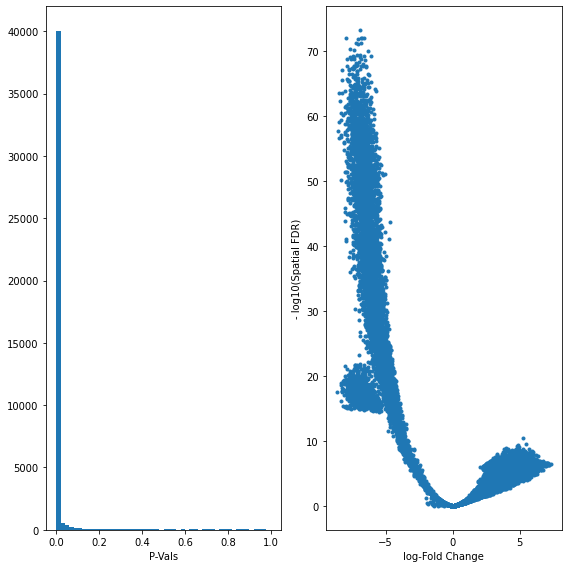

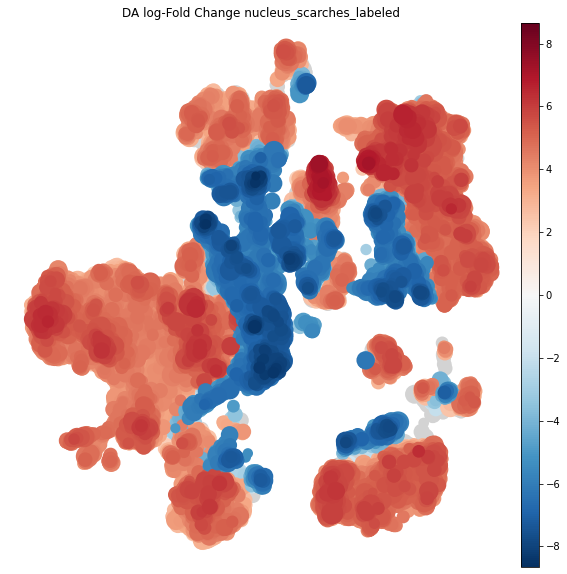

Show plot: Top cell label fraction per neighborhood.
Show plot: logFC values per cell label type grouped neighborhood.


/opt/python/lib/python3.8/site-packages/anndata/_core/anndata.py:1228: FutureWarning: The `inplace` parameter in pandas.Categorical.reorder_categories is deprecated and will be removed in a future version. Reordering categories will always return a new Categorical object.
  c.reorder_categories(natsorted(c.categories), inplace=True)
... storing 'nhood_annotation' as categorical
/home/jan.domke/.ch_tmp/ipykernel_197270/3099720966.py:25: RuntimeWarning: invalid value encountered in true_divide
  cells_DA_avg = cells_nh_DA_avg.sum(axis=1).A1/cells_nh_DA.getnnz(axis=1)


Save model...


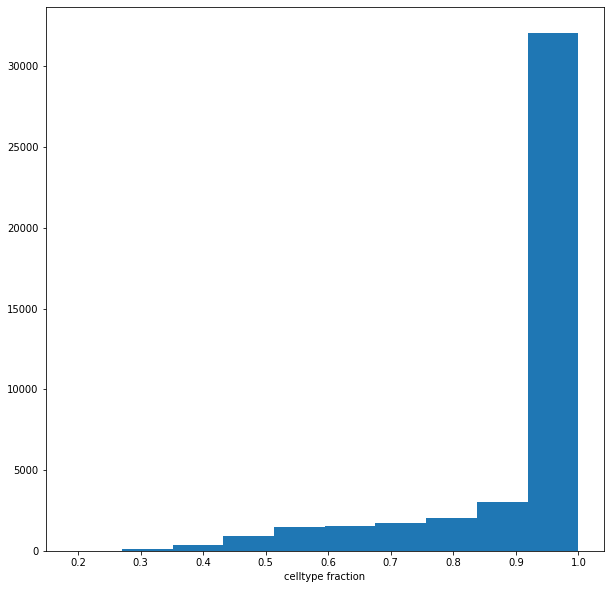

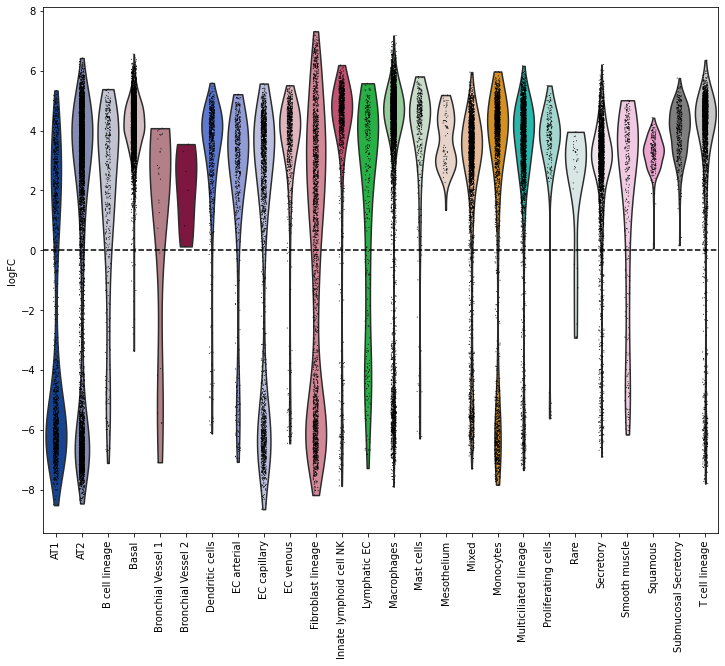

In [8]:
scarches_labeled = run_milo_workflow(adata = scarches_labeled, name = "nucleus_scarches_labeled", embedding = "scArches",
                                     query_dataset= query_dataset_nucleus, save_loc=save_loc_nucleus, k=150)

In [20]:
#Separately save logFC values for k=150
denovo_recalc_logFC_avg = denovo_recalc.obs.logFC_avg
denovo_ref_logFC_avg = denovo_ref.obs.logFC_avg
scarches_unlabeled_logFC_avg = scarches_unlabeled.obs.logFC_avg
scarches_labeled_logFC_avg = scarches_labeled.obs.logFC_avg

denovo_recalc_logFC_avg.to_pickle("/storage/groups/ml01/workspace/jan.domke/Data/Data_Milo/New_higher_k/nucleus_denovo_recalc_logFC.h5ad")
denovo_ref_logFC_avg.to_pickle("/storage/groups/ml01/workspace/jan.domke/Data/Data_Milo/New_higher_k/nucleus_denovo_ref_logFC.h5ad")
scarches_unlabeled_logFC_avg.to_pickle("/storage/groups/ml01/workspace/jan.domke/Data/Data_Milo/New_higher_k/nucleus_scarches_unlabeled_logFC.h5ad")
scarches_labeled_logFC_avg.to_pickle("/storage/groups/ml01/workspace/jan.domke/Data/Data_Milo/New_higher_k/nucleus_scarches_labeled_logFC.h5ad")

In [9]:
scarches_labeled_logFC_avg = scarches_labeled.obs.logFC_avg
scarches_labeled_logFC_avg.to_pickle("/storage/groups/ml01/workspace/jan.domke/Data/Data_Milo/New_higher_k/nucleus_scarches_labeled_logFC_II.h5ad")

### 4. Milo on disease/healthy for IPF data
Only for scArches unlabeled to compare Milo results (disease/healthy vs. query/reference) in T+NK-cell cluster.

In [21]:
scarches_unlabeled = sc.read("/storage/groups/ml01/workspace/jan.domke/Data/Models/IPF/learned_atlas/IPF_atlas_scArches_full.h5ad")
denovo_recalc = sc.read("/storage/groups/ml01/workspace/jan.domke/Data/Models/IPF/learned_atlas/IPF_atlas_denovo.h5ad")

computing neighbors
    finished: added to `.uns['neighbors']`
    `.obsp['distances']`, distances for each pair of neighbors
    `.obsp['connectivities']`, weighted adjacency matrix (0:22:55)
computing UMAP
    finished: added
    'X_umap', UMAP coordinates (adata.obsm) (0:45:51)


... storing 'age' as categorical


Show plot: UMAP of ipf_scarches_unlabeled showing scanvi_label, dataset and condition.


... storing 'condition_milo' as categorical


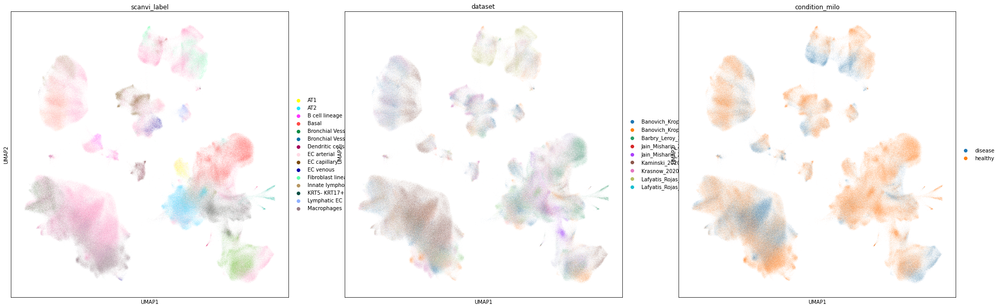

Show plot: log-Fold Changes for ipf_scarches_unlabeled
Show plot: UMAP neighborhood graph with logFC values.


/opt/python/lib/python3.8/site-packages/anndata/_core/anndata.py:120: ImplicitModificationWarning: Transforming to str index.
  warnings.warn("Transforming to str index.", ImplicitModificationWarning)


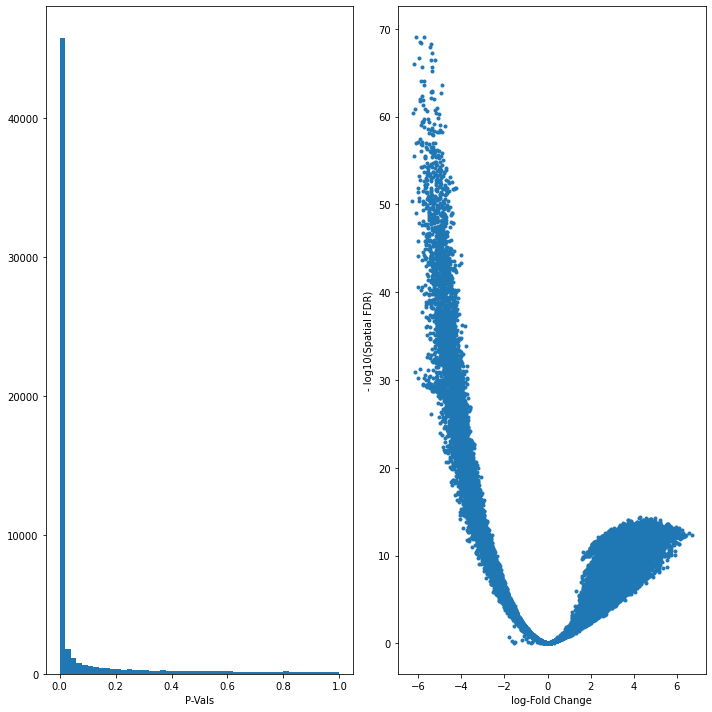

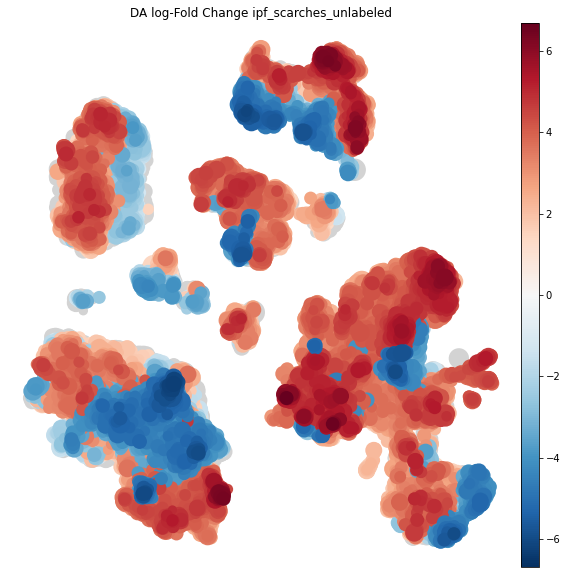

Show plot: Top cell label fraction per neighborhood.


... storing 'nhood_annotation' as categorical


Show plot: logFC values per cell label type grouped neighborhood.


/home/jan.domke/.ch_tmp/ipykernel_322260/3099720966.py:25: RuntimeWarning: invalid value encountered in true_divide
  cells_DA_avg = cells_nh_DA_avg.sum(axis=1).A1/cells_nh_DA.getnnz(axis=1)


Save model...


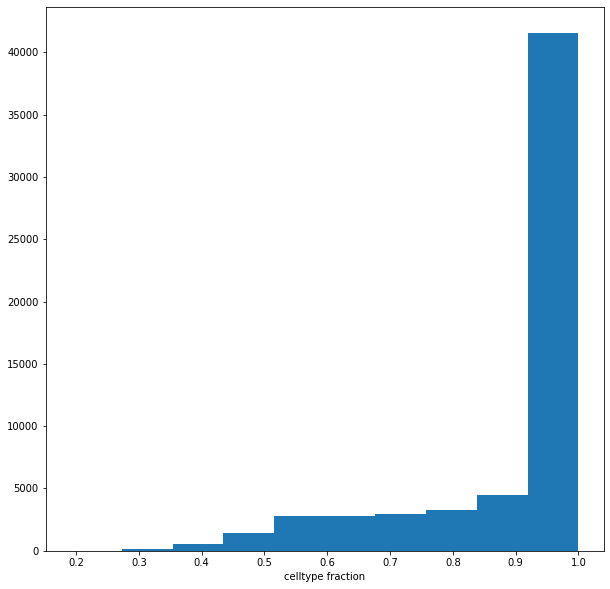

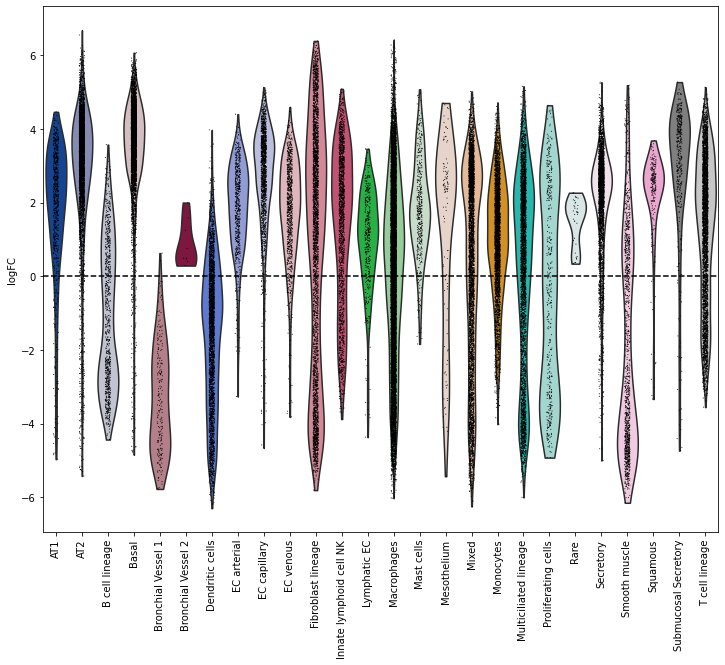

In [22]:
scarches_unlabeled = run_milo_workflow(adata = scarches_unlabeled, name = "ipf_scarches_unlabeled", embedding = "scArches", query_dataset= query_dataset_ipf,
                                       save_loc=save_loc_ipf, k=150, version = "disease/healthy")

computing neighbors
    finished: added to `.uns['neighbors']`
    `.obsp['distances']`, distances for each pair of neighbors
    `.obsp['connectivities']`, weighted adjacency matrix (0:22:45)
computing UMAP
    finished: added
    'X_umap', UMAP coordinates (adata.obsm) (0:45:41)


... storing 'condition_milo' as categorical


Show plot: UMAP of ipf_denovo_recalc showing scanvi_label, dataset and condition.


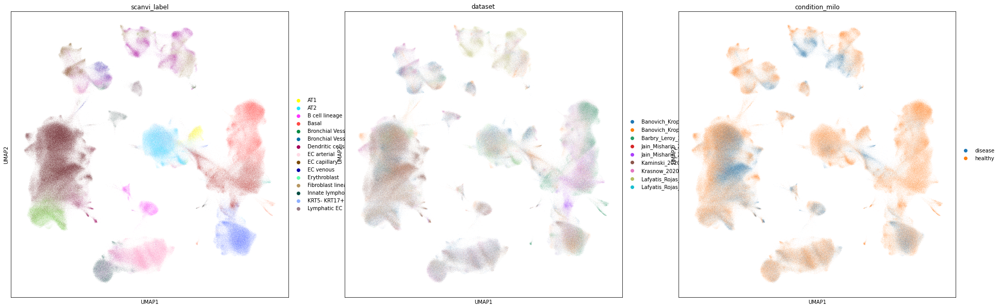

Show plot: Distribution of neighborhood sizes.


/opt/python/lib/python3.8/site-packages/anndata/_core/anndata.py:120: ImplicitModificationWarning: Transforming to str index.
  warnings.warn("Transforming to str index.", ImplicitModificationWarning)
/opt/python/lib/python3.8/site-packages/anndata/_core/anndata.py:801: UserWarning: 
AnnData expects .var.index to contain strings, but got values like:
    ['001C', '002C', '003C', '010I', '021I']

    Inferred to be: categorical

  value_idx = self._prep_dim_index(value.index, attr)


Show plot: log-Fold Changes for ipf_denovo_recalc
Show plot: UMAP neighborhood graph with logFC values.


/opt/python/lib/python3.8/site-packages/anndata/_core/anndata.py:120: ImplicitModificationWarning: Transforming to str index.
  warnings.warn("Transforming to str index.", ImplicitModificationWarning)


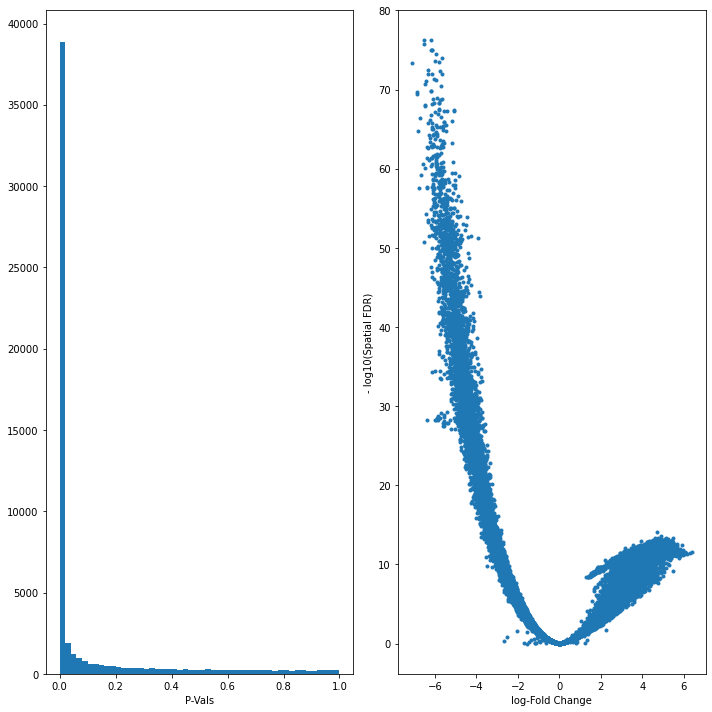

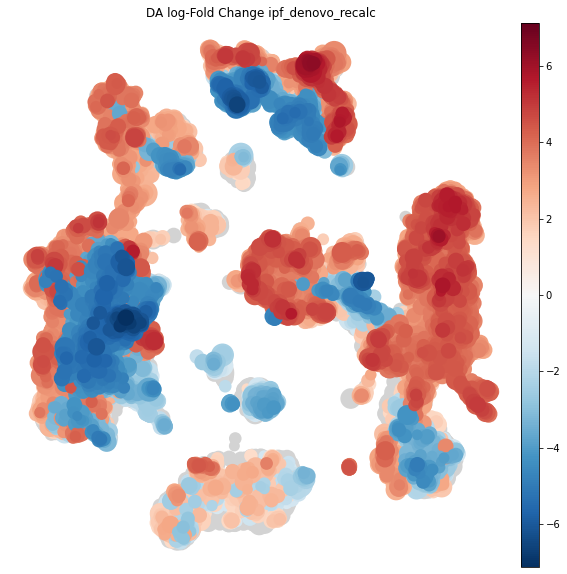

Show plot: Top cell label fraction per neighborhood.


... storing 'nhood_annotation' as categorical


Show plot: logFC values per cell label type grouped neighborhood.


/home/jan.domke/.ch_tmp/ipykernel_322260/3099720966.py:25: RuntimeWarning: invalid value encountered in true_divide
  cells_DA_avg = cells_nh_DA_avg.sum(axis=1).A1/cells_nh_DA.getnnz(axis=1)


Save model...


... storing 'highly_variable_intersection-0' as categorical


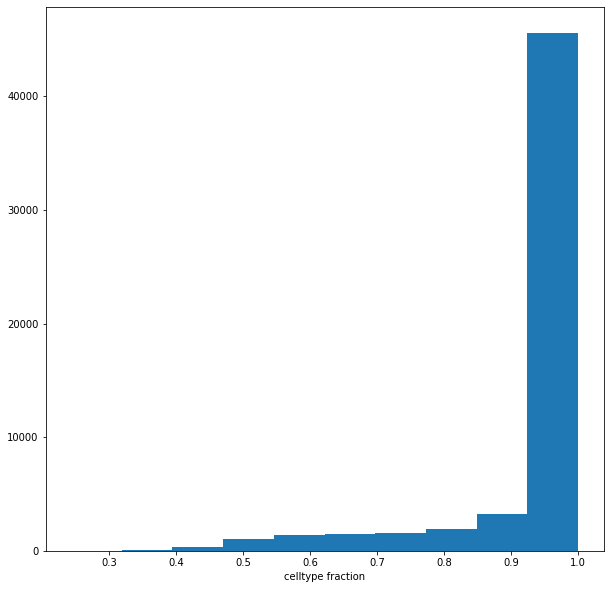

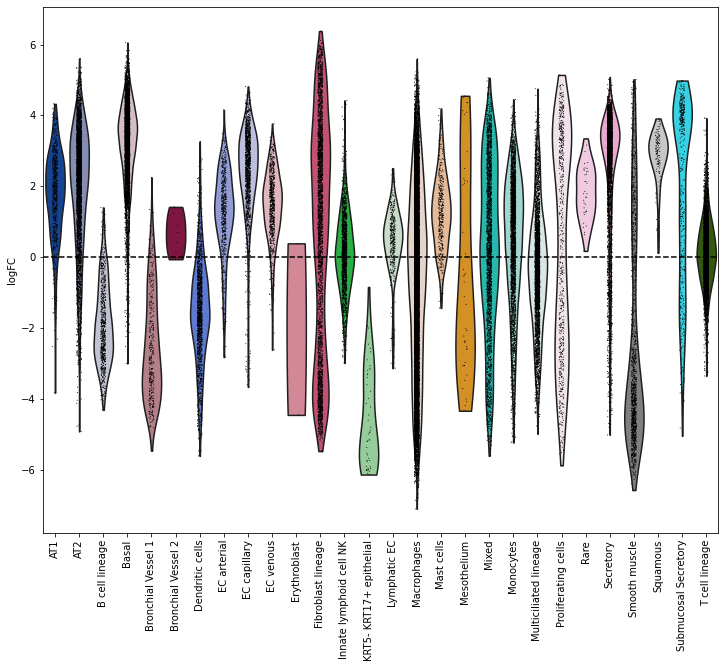

In [24]:
denovo_recalc = run_milo_workflow(adata = denovo_recalc, name = "ipf_denovo_recalc", embedding = "scANVI", query_dataset = query_dataset_ipf,
                                       save_loc=save_loc_ipf, k=150, version = "disease/healthy")

In [26]:
denovo_recalc_logFC_avg_disease_healthy = denovo_recalc.obs.logFC_avg
scarches_unlabeled_logFC_avg_disease_healthy = scarches_unlabeled.obs.logFC_avg

denovo_recalc_logFC_avg_disease_healthy.to_pickle("/storage/groups/ml01/workspace/jan.domke/Data/Data_Milo/New_higher_k/ipf_denovo_recalc_logFC_disease_healthy.h5ad")
scarches_unlabeled_logFC_avg_disease_healthy.to_pickle("/storage/groups/ml01/workspace/jan.domke/Data/Data_Milo/New_higher_k/ipf_scarches_unlabeled_logFC_disease_healthy.h5ad")

### 5. Rerun disease/healthy and query/reference for IPF scArches unlabeled

This step was neeeded to obtain original logFC and P values for neighborhoods, as those could not be saved together with the other Milo values inside the adata object and thus were not available anymore.

In [ ]:
#Import learned atlas ipf
scarches_unlabeled = sc.read("/storage/groups/ml01/workspace/jan.domke/Data/Models/IPF/learned_atlas/IPF_atlas_scArches_full.h5ad")

#### 5.1 scArches unlabeled query/reference

In [10]:
adata = scarches_unlabeled.copy()
name = "ipf_scarches_unlabeled_query_reference"
embedding = "scArches"
query_dataset= query_dataset_ipf
save_loc=save_loc_ipf
k=150
n=30

In [11]:
adata.obs["condition_milo"] = "reference"
adata.obs.loc[adata.obs.dataset.isin(query_dataset),"condition_milo"] = "query"

computing neighbors


2022-01-24 17:46:41.410321: W tensorflow/stream_executor/platform/default/dso_loader.cc:64] Could not load dynamic library 'libcudart.so.11.0'; dlerror: libcudart.so.11.0: cannot open shared object file: No such file or directory; LD_LIBRARY_PATH: /opt/R/lib/R/lib
2022-01-24 17:46:41.410353: I tensorflow/stream_executor/cuda/cudart_stub.cc:29] Ignore above cudart dlerror if you do not have a GPU set up on your machine.


    finished: added to `.uns['neighbors']`
    `.obsp['distances']`, distances for each pair of neighbors
    `.obsp['connectivities']`, weighted adjacency matrix (0:23:38)
computing UMAP
    finished: added
    'X_umap', UMAP coordinates (adata.obsm) (0:48:16)


... storing 'age' as categorical


Show plot: UMAP of ipf_scarches_unlabeled_query_reference showing scanvi_label, dataset and condition.


... storing 'condition_milo' as categorical


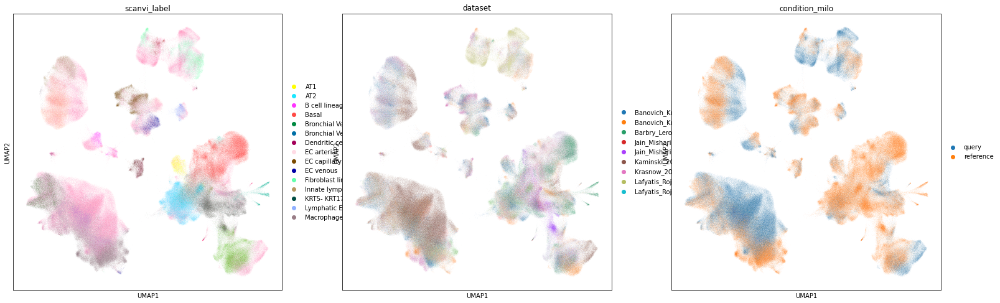

In [12]:
sc.pp.neighbors(adata, n_neighbors=k, n_pcs=n, use_rep="X_"+embedding)
sc.tl.umap(adata)
print("Show plot: UMAP of "+ name + " showing scanvi_label, dataset and condition.")
sc.pl.umap(adata, color=["scanvi_label","dataset", "condition_milo"])

In [13]:
# Construct milo neighborhoods: assign cells to a set of representative neighbourhoods on the KNN graph. Assignment is stored in adata.obsm["nhoods"] 
milo.make_nhoods(adata, prop=0.1)


In [14]:
# Count how many cells from each sample (=sample_col) are in each neighborhood. 
# This adds adata.uns["nhood_adata"], storing an anndata object where obs correespond to neighborhoods, var corresponds to samples and  .X stores the number of cells from each sample counted in a neighborhood.
milo.count_nhoods(adata, sample_col="sample")
# Test for differential abundance using condition_milo as condition
adata.obs["condition_milo_continuous"] = adata.obs["condition_milo"].cat.codes
milo.DA_nhoods(adata, design="~condition_milo_continuous")

/opt/python/lib/python3.8/site-packages/anndata/_core/anndata.py:120: ImplicitModificationWarning: Transforming to str index.
  warnings.warn("Transforming to str index.", ImplicitModificationWarning)
/opt/python/lib/python3.8/site-packages/anndata/_core/anndata.py:801: UserWarning: 
AnnData expects .var.index to contain strings, but got values like:
    ['001C', '002C', '003C', '010I', '021I']

    Inferred to be: categorical

  value_idx = self._prep_dim_index(value.index, attr)


In [15]:
# Build abstracted graph of neighborhoods, where each node represents a neighborhood and each edge indicate how many cells two neighborhoods have in common
# Position of neighborhood node is given by position in UMAP of index cell of respective neihgborhood. Color is given by their log-Fold change.
milopy.utils.build_nhood_graph(adata)

Show plot: Top cell label fraction per neighborhood.


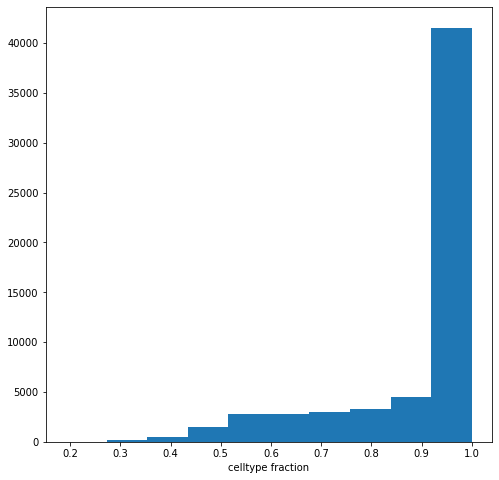

In [16]:
# Assign cell type label to each neighborhood using the most prominent cell type within each neighborhood.
# Plot cell label fraction per neighborhood and rename neighborhoods with less than 60% of cell are top label as "Mixed".
milopy.utils.annotate_nhoods(adata, anno_col="C_"+embedding)
print("Show plot: Top cell label fraction per neighborhood.")
plt.hist(adata.uns['nhood_adata'].obs["nhood_annotation_frac"]);
plt.xlabel("celltype fraction")

adata.uns['nhood_adata'].obs.loc[adata.uns['nhood_adata'].obs["nhood_annotation_frac"] < 0.6, "nhood_annotation"] = "Mixed"


In [17]:
# Calculate average logFC for all cells over the nhoods this cell is part of
adata.obs["logFC_avg"] = get_avg_da_per_cell(adata)

/home/jan.domke/.ch_tmp/ipykernel_140828/3099720966.py:25: RuntimeWarning: invalid value encountered in true_divide
  cells_DA_avg = cells_nh_DA_avg.sum(axis=1).A1/cells_nh_DA.getnnz(axis=1)


In [ ]:
#Save original logFC and P values per neighborhood
adata.uns["nhood_adata"].write("scarches_healthy_disease_milo_nhoods.h5ad")

#### 5.2 scArches unlabeled disease/healthy

In [20]:
adata2 = scarches_unlabeled.copy()
name = "ipf_scarches_unlabeled_query_reference"
embedding = "scArches"
query_dataset= query_dataset_ipf
save_loc=save_loc_ipf
k=150
n=30

In [21]:
adata2.obs["condition_milo"] = "healthy"
adata2.obs.loc[adata2.obs.condition=="IPF","condition_milo"] = "disease"

computing neighbors
    finished: added to `.uns['neighbors']`
    `.obsp['distances']`, distances for each pair of neighbors
    `.obsp['connectivities']`, weighted adjacency matrix (0:23:30)
computing UMAP
    finished: added
    'X_umap', UMAP coordinates (adata.obsm) (0:51:01)


... storing 'age' as categorical


Show plot: UMAP of ipf_scarches_unlabeled_query_reference showing scanvi_label, dataset and condition.


... storing 'condition_milo' as categorical


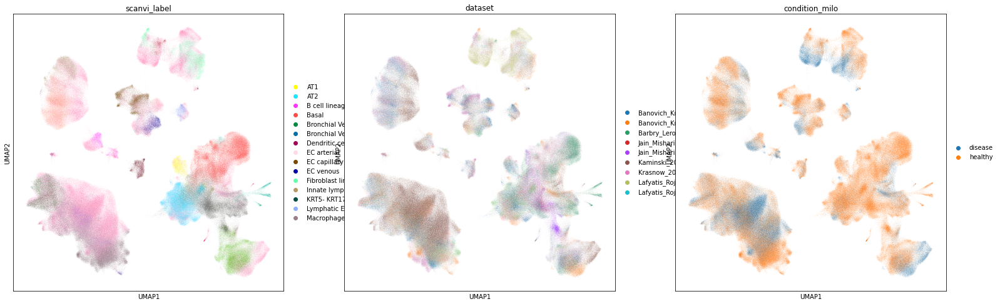

In [22]:
sc.pp.neighbors(adata2, n_neighbors=k, n_pcs=n, use_rep="X_"+embedding)
sc.tl.umap(adata2)
print("Show plot: UMAP of "+ name + " showing scanvi_label, dataset and condition.")
sc.pl.umap(adata2, color=["scanvi_label","dataset", "condition_milo"])

In [23]:
# Construct milo neighborhoods: assign cells to a set of representative neighbourhoods on the KNN graph. Assignment is stored in adata2.obsm["nhoods"] 
milo.make_nhoods(adata2, prop=0.1)


In [24]:
# Count how many cells from each sample (=sample_col) are in each neighborhood. 
# This adds adata2.uns["nhood_adata2"], storing an anndata object where obs correespond to neighborhoods, var corresponds to samples and  .X stores the number of cells from each sample counted in a neighborhood.
milo.count_nhoods(adata2, sample_col="sample")
# Test for differential abundance using condition_milo as condition
adata2.obs["condition_milo_continuous"] = adata2.obs["condition_milo"].cat.codes
milo.DA_nhoods(adata2, design="~condition_milo_continuous")

/opt/python/lib/python3.8/site-packages/anndata/_core/anndata.py:120: ImplicitModificationWarning: Transforming to str index.
  warnings.warn("Transforming to str index.", ImplicitModificationWarning)
/opt/python/lib/python3.8/site-packages/anndata/_core/anndata.py:801: UserWarning: 
AnnData expects .var.index to contain strings, but got values like:
    ['001C', '002C', '003C', '010I', '021I']

    Inferred to be: categorical

  value_idx = self._prep_dim_index(value.index, attr)


In [25]:
# Build abstracted graph of neighborhoods, where each node represents a neighborhood and each edge indicate how many cells two neighborhoods have in common
# Position of neighborhood node is given by position in UMAP of index cell of respective neihgborhood. Color is given by their log-Fold change.
milopy.utils.build_nhood_graph(adata2)

Show plot: Top cell label fraction per neighborhood.


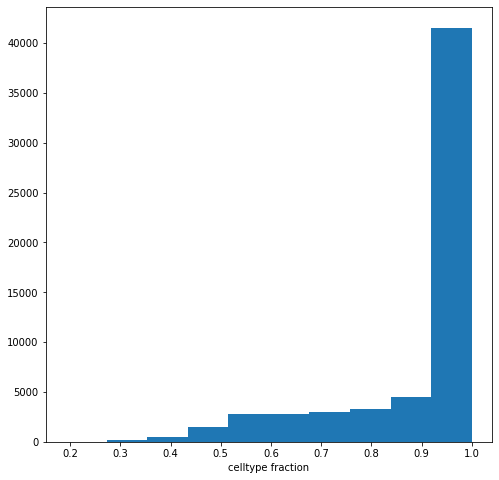

In [27]:
# Assign cell type label to each neighborhood using the most prominent cell type within each neighborhood.
# Plot cell label fraction per neighborhood and rename neighborhoods with less than 60% of cell are top label as "Mixed".
milopy.utils.annotate_nhoods(adata2, anno_col="C_"+embedding)
print("Show plot: Top cell label fraction per neighborhood.")
plt.hist(adata2.uns['nhood_adata'].obs["nhood_annotation_frac"]);
plt.xlabel("celltype fraction")

adata2.uns['nhood_adata'].obs.loc[adata2.uns['nhood_adata'].obs["nhood_annotation_frac"] < 0.6, "nhood_annotation"] = "Mixed"


In [28]:
# Calculate average logFC for all cells over the nhoods this cell is part of
adata2.obs["logFC_avg"] = get_avg_da_per_cell(adata2)

/home/jan.domke/.ch_tmp/ipykernel_140828/3099720966.py:25: RuntimeWarning: invalid value encountered in true_divide
  cells_DA_avg = cells_nh_DA_avg.sum(axis=1).A1/cells_nh_DA.getnnz(axis=1)


In [ ]:
#Save original logFC and P values per neighborhood
adata2.uns["nhood_adata"].write("scarches_query_ref_milo_nhoods.h5ad")

#### 5.3 Compare pValues for Milo disease/healthy vs query/reference for T and NK cells

In [7]:
milo_disease_healthy = sc.read("/storage/groups/ml01/workspace/jan.domke/Data/Data_Milo/New_higher_k/Pvalues_nhoods/scarches_healthy_disease_milo_nhoods.h5ad")
milo_query_reference = sc.read("/storage/groups/ml01/workspace/jan.domke/Data/Data_Milo/New_higher_k/Pvalues_nhoods/scarches_query_ref_milo_nhoods.h5ad")

/opt/python/lib/python3.8/site-packages/anndata/_core/anndata.py:120: ImplicitModificationWarning: Transforming to str index.
  warnings.warn("Transforming to str index.", ImplicitModificationWarning)
/opt/python/lib/python3.8/site-packages/anndata/_core/anndata.py:120: ImplicitModificationWarning: Transforming to str index.
  warnings.warn("Transforming to str index.", ImplicitModificationWarning)


In [8]:
#Separate datasets by NK and T cells
milo_disease_healthy_nk = milo_disease_healthy[milo_disease_healthy.obs.nhood_annotation=="Innate lymphoid cell NK"]
milo_disease_healthy_t = milo_disease_healthy[milo_disease_healthy.obs.nhood_annotation=="T cell lineage"]
milo_query_reference_nk = milo_query_reference[milo_query_reference.obs.nhood_annotation=="Innate lymphoid cell NK"]
milo_query_reference_t = milo_query_reference[milo_query_reference.obs.nhood_annotation=="T cell lineage"]

In [9]:
# Calculate log10 values of pvalues to better differentiate small values
milo_disease_healthy_nk.obs["PValue_log"] = np.log10(milo_disease_healthy_nk.obs.PValue)
milo_query_reference_nk.obs["PValue_log"] = np.log10(milo_query_reference_nk.obs.PValue)
milo_disease_healthy_t.obs["PValue_log"] = np.log10(milo_disease_healthy_t.obs.PValue)
milo_query_reference_t.obs["PValue_log"] = np.log10(milo_query_reference_t.obs.PValue)

Trying to set attribute `.obs` of view, copying.
Trying to set attribute `.obs` of view, copying.
Trying to set attribute `.obs` of view, copying.
Trying to set attribute `.obs` of view, copying.


In [37]:
#plot log10(Pvalues) -> lower values show the smaller original pvalues ->differential abundance is more significant for query vs reference
# than for disease vs healthy

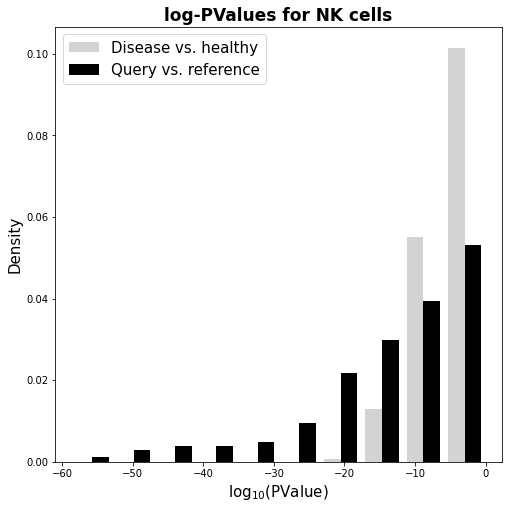

In [10]:
plt.hist([milo_disease_healthy_nk.obs.PValue_log,milo_query_reference_nk.obs.PValue_log], density=True, 
         label = ["Disease vs. healthy", "Query vs. reference"],color=["lightgrey","black"])
plt.title("log-PValues for NK cells",fontweight="bold",size=17)
plt.xlabel(r"$\log_{10}$(PValue)",size=15)
plt.ylabel("Density",size=15)
plt.legend(prop={'size': 15})
plt.savefig("pvalues_dist_milo_NK_cells.png")

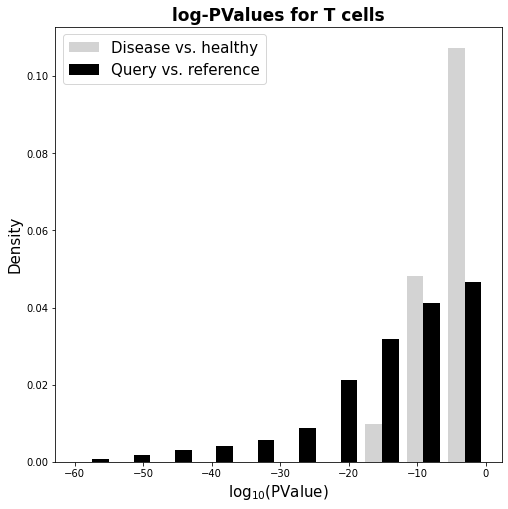

In [11]:
plt.hist([milo_disease_healthy_t.obs.PValue_log,milo_query_reference_t.obs.PValue_log], density=True,
         label = ["Disease vs. healthy", "Query vs. reference"], bins=10,color=["lightgrey","black"])
plt.title("log-PValues for T cells",fontweight="bold",size=17)
plt.xlabel(r"$\log_{10}$(PValue)",size=15)
plt.ylabel("Density",size=15)
plt.legend(prop={'size': 15})
plt.savefig("pvalues_dist_milo_T_cells.png")

In [92]:
sc.logging.print_versions()


The `sinfo` package has changed name and is now called `session_info` to become more discoverable and self-explanatory. The `sinfo` PyPI package will be kept around to avoid breaking old installs and you can downgrade to 0.3.2 if you want to use it without seeing this message. For the latest features and bug fixes, please install `session_info` instead. The usage and defaults also changed slightly, so please review the latest README at https://gitlab.com/joelostblom/session_info.
-----
anndata     0.7.8
scanpy      1.8.2
sinfo       0.3.4
-----
PIL                         8.4.0
anyio                       NA
asciitree                   NA
attr                        21.2.0
babel                       2.9.1
backcall                    0.2.0
backports                   NA
beta_ufunc                  NA
binom_ufunc                 NA
brotli                      1.0.9
certifi                     2021.10.08
cffi                        1.15.0
chardet                     4.0.0
charset_normali